<a href="https://colab.research.google.com/github/aniketkoley-iisc/ev-gap-analysis-india-upm/blob/main/notebooks/ev-gap-analysis-india-upm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#CELL 1 START STAGE 0: ENVIRONMENT & LAKEHOUSE INITIALIZATION

import os
import subprocess
from google.colab import drive

# 1. Mount Google Drive for persistent Bronze/Silver/Gold storage
drive.mount('/content/drive', force_remount=False)

DRIVE_ROOT = "/content/drive/MyDrive/EV_Gap_Project_UPM"
LOCAL_DATA = "/content/data"
for base in [DRIVE_ROOT, LOCAL_DATA]:
    for tier in ["bronze", "silver", "gold"]:
        os.makedirs(f"{base}/{tier}", exist_ok=True)

# 2. Clone or update the new GitHub repository
REPO_URL = "https://github.com/aniketkoley-iisc/ev-gap-analysis-india-upm.git"
REPO_DIR = "/content/ev-gap-analysis-india-upm"

if not os.path.exists(REPO_DIR):
    subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=False)
else:
    subprocess.run(["git", "-C", REPO_DIR, "pull"], check=False)

print("Lakehouse directories ready:")
print(f"   Persistent Google Drive: {DRIVE_ROOT}/{{bronze,silver,gold}}")
print(f"   Fast Local Colab Disk  : {LOCAL_DATA}/{{bronze,silver,gold}}")

### CELL 1 END STAGE 0

Mounted at /content/drive
Lakehouse directories ready:
   Persistent Google Drive: /content/drive/MyDrive/EV_Gap_Project_UPM/{bronze,silver,gold}
   Fast Local Colab Disk  : /content/data/{bronze,silver,gold}


In [3]:
#CELL 2 START STAGE 0.2: SPARK SESSION INITIALIZATION

!pip install -q pyspark osmium h3 requests pyarrow pandas

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *

spark = (
    SparkSession.builder
    .appName("EV-Gap-Lakehouse-India-UPM")
    .master("local[*]")
    .config("spark.driver.memory", "10g")
    .config("spark.executor.memory", "10g")
    .config("spark.memory.offHeap.enabled", "true")
    .config("spark.memory.offHeap.size", "2g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .config("spark.sql.parquet.compression.codec", "snappy")
    .getOrCreate()
)

sc = spark.sparkContext
sc.setLogLevel("WARN")
print(f"Spark {spark.version} Initialized | Master: {sc.master} | Parallelism: {sc.defaultParallelism}")

### 0.2 END STAGE 0.2

Spark 4.0.5 Initialized | Master: local[*] | Parallelism: 2


In [4]:
#CELL 3 START STAGE 1A: GEOFABRIK INDIA OSM PBF & LIVE OVERPASS API (WITH LIVE vs LOCAL/REMOTE COMPARISON)

import os
import json
import shutil
import urllib.request
import requests

BRONZE_DIR = "/content/data/bronze"
DRIVE_BRONZE = "/content/drive/MyDrive/EV_Gap_Project_UPM/bronze"
LEGACY_DRIVE_BRONZE = "/content/drive/MyDrive/EV_Gap_Project/bronze"
os.makedirs(BRONZE_DIR, exist_ok=True)
os.makedirs(DRIVE_BRONZE, exist_ok=True)

STRICT_LIVE_MATCH = False
HTTP_HEADERS = {
    "User-Agent": "IISc-DA231O-EVGapAnalysis/1.0 (Academic Research; aniketkoley@iisc.ac.in)",
    "Accept": "application/json, application/octet-stream, */*"
}

# -------------------------------------------------------------------------
# 1. FULL-SCALE INDIA GEOFABRIK OSM PBF (LIVE METADATA vs LOCAL/REMOTE CHECK)
# -------------------------------------------------------------------------
OSM_PBF_URL = "https://download.geofabrik.de/asia/india-latest.osm.pbf"
OSM_PBF_LOCAL = f"{BRONZE_DIR}/india-latest.osm.pbf"
OSM_PBF_DRIVE = f"{DRIVE_BRONZE}/india-latest.osm.pbf"
OSM_PBF_LEGACY = f"{LEGACY_DRIVE_BRONZE}/india-latest.osm.pbf"

live_pbf_bytes = 0
live_last_modified = "Unknown"
try:
    head_resp = requests.head(OSM_PBF_URL, headers=HTTP_HEADERS, allow_redirects=True, timeout=10)
    live_pbf_bytes = int(head_resp.headers.get("Content-Length", 0))
    live_last_modified = head_resp.headers.get("Last-Modified", "Unknown")
except Exception:
    pass

local_pbf_bytes = os.path.getsize(OSM_PBF_LOCAL) if os.path.exists(OSM_PBF_LOCAL) else 0
drive_pbf_bytes = os.path.getsize(OSM_PBF_DRIVE) if os.path.exists(OSM_PBF_DRIVE) else 0
legacy_pbf_bytes = os.path.getsize(OSM_PBF_LEGACY) if os.path.exists(OSM_PBF_LEGACY) else 0

print("=== GEOFABRIK INDIA OSM PBF: LIVE SERVER vs LOCAL / REMOTE STORAGE COMPARISON ===")
if live_pbf_bytes > 0:
    print(f"   Live Geofabrik Server : {live_pbf_bytes / (1024**3):.4f} GB ({live_pbf_bytes:,} bytes) | Last-Modified: {live_last_modified}")
else:
    print("   Live Geofabrik Server : Metadata check skipped (using verified local/remote size >= 1.50 GB)")
print(f"   Local Colab Disk      : {local_pbf_bytes / (1024**3):.4f} GB ({local_pbf_bytes:,} bytes)")
print(f"   Remote Google Drive   : {drive_pbf_bytes / (1024**3):.4f} GB ({drive_pbf_bytes:,} bytes)")

def _is_valid_pbf(file_bytes, ref_live_bytes, strict=False):
    if file_bytes < 500_000_000:
        return False
    if strict and ref_live_bytes > 0:
        return file_bytes == ref_live_bytes
    return True

if _is_valid_pbf(local_pbf_bytes, live_pbf_bytes, STRICT_LIVE_MATCH):
    print("[DECISION -> SKIP DOWNLOAD] Local Colab disk already has a valid india-latest.osm.pbf!")
    if not _is_valid_pbf(drive_pbf_bytes, live_pbf_bytes, False):
        shutil.copy2(OSM_PBF_LOCAL, OSM_PBF_DRIVE)
elif _is_valid_pbf(drive_pbf_bytes, live_pbf_bytes, STRICT_LIVE_MATCH):
    print("[DECISION -> SKIP INTERNET DOWNLOAD] Copying verified india-latest.osm.pbf from Remote Google Drive (EV_Gap_Project_UPM)...")
    shutil.copy2(OSM_PBF_DRIVE, OSM_PBF_LOCAL)
elif _is_valid_pbf(legacy_pbf_bytes, live_pbf_bytes, STRICT_LIVE_MATCH):
    print("[DECISION -> SKIP INTERNET DOWNLOAD] Syncing verified india-latest.osm.pbf from existing Google Drive storage...")
    shutil.copy2(OSM_PBF_LEGACY, OSM_PBF_LOCAL)
    shutil.copy2(OSM_PBF_LOCAL, OSM_PBF_DRIVE)
else:
    print("[DECISION -> DOWNLOAD REQUIRED] Downloading india-latest.osm.pbf from live Geofabrik server...")
    urllib.request.urlretrieve(OSM_PBF_URL, OSM_PBF_LOCAL)
    shutil.copy2(OSM_PBF_LOCAL, OSM_PBF_DRIVE)

pbf_size_gb = os.path.getsize(OSM_PBF_LOCAL) / (1024**3)
print(f"[DONE] Geofabrik India OSM PBF Ready at {OSM_PBF_LOCAL} ({pbf_size_gb:.2f} GB)\n")

# -------------------------------------------------------------------------
# 2. LIVE OVERPASS API CHARGING STATIONS (LOCAL / REMOTE vs LIVE API CHECK)
# -------------------------------------------------------------------------
OVERPASS_JSON_LOCAL = f"{BRONZE_DIR}/osm_india_charging_stations_live.json"
OVERPASS_JSON_DRIVE = f"{DRIVE_BRONZE}/osm_india_charging_stations_live.json"
OVERPASS_JSON_LEGACY = f"{LEGACY_DRIVE_BRONZE}/osm_india_charging_stations_live.json"

local_json_bytes = os.path.getsize(OVERPASS_JSON_LOCAL) if os.path.exists(OVERPASS_JSON_LOCAL) else 0
drive_json_bytes = os.path.getsize(OVERPASS_JSON_DRIVE) if os.path.exists(OVERPASS_JSON_DRIVE) else 0
legacy_json_bytes = os.path.getsize(OVERPASS_JSON_LEGACY) if os.path.exists(OVERPASS_JSON_LEGACY) else 0

print("=== OVERPASS API CHARGING STATIONS: LOCAL / REMOTE STORAGE CHECK ===")
print(f"   Local Colab JSON Size : {local_json_bytes / 1024:.1f} KB")
print(f"   Google Drive JSON Size: {max(drive_json_bytes, legacy_json_bytes) / 1024:.1f} KB")

if local_json_bytes > 10_000 and not STRICT_LIVE_MATCH:
    print("[DECISION -> SKIP API CALL] Valid Overpass charging station snapshot already on local Colab disk!")
    if drive_json_bytes <= 10_000:
        shutil.copy2(OVERPASS_JSON_LOCAL, OVERPASS_JSON_DRIVE)
elif drive_json_bytes > 10_000 and not STRICT_LIVE_MATCH:
    print("[DECISION -> SKIP API CALL] Copying verified Overpass charging station snapshot from Google Drive (EV_Gap_Project_UPM)...")
    shutil.copy2(OVERPASS_JSON_DRIVE, OVERPASS_JSON_LOCAL)
elif legacy_json_bytes > 10_000 and not STRICT_LIVE_MATCH:
    print("[DECISION -> SKIP API CALL] Syncing verified Overpass charging station snapshot from Google Drive...")
    shutil.copy2(OVERPASS_JSON_LEGACY, OVERPASS_JSON_LOCAL)
    shutil.copy2(OVERPASS_JSON_LOCAL, OVERPASS_JSON_DRIVE)
else:
    print("[DECISION -> QUERY LIVE API] Querying live OpenStreetMap Overpass API mirrors for amenity=charging_station across India...")
    overpass_query = '[out:json][timeout:120];area["ISO3166-1"="IN"]->.searchArea;(node["amenity"="charging_station"](area.searchArea);way["amenity"="charging_station"](area.searchArea);relation["amenity"="charging_station"](area.searchArea););out center tags;'
    overpass_mirrors = [
        "https://overpass.kumi.systems/api/interpreter",
        "https://lz4.overpass-api.de/api/interpreter",
        "https://overpass-api.de/api/interpreter",
        "https://maps.mail.ru/osm/tools/overpass/api/interpreter"
    ]
    fetched_ok = False
    for mirror_url in overpass_mirrors:
        try:
            resp = requests.post(
                mirror_url,
                data={"data": overpass_query},
                headers=HTTP_HEADERS,
                timeout=120
            )
            if resp.status_code == 200 and len(resp.text) > 5000 and '"elements"' in resp.text:
                with open(OVERPASS_JSON_LOCAL, "w", encoding="utf-8") as f:
                    f.write(resp.text)
                shutil.copy2(OVERPASS_JSON_LOCAL, OVERPASS_JSON_DRIVE)
                print(f"[DONE] Successfully fetched live Overpass JSON from mirror: {mirror_url}")
                fetched_ok = True
                break
        except Exception as e:
            print(f"[INFO] Mirror {mirror_url} busy ({e}), trying next mirror...")

with open(OVERPASS_JSON_LOCAL, "r", encoding="utf-8") as f:
    elements = json.load(f).get("elements", [])
print(f"[DONE] Live Overpass API India Charging Stations Ready: {len(elements):,} raw OSM station records!")

### 0.3 END STAGE 1A

=== GEOFABRIK INDIA OSM PBF: LIVE SERVER vs LOCAL / REMOTE STORAGE COMPARISON ===
   Live Geofabrik Server : 1.5969 GB (1,714,622,832 bytes) | Last-Modified: Tue, 10 Nov 2026 08:22:30 GMT
   Local Colab Disk      : 0.0000 GB (0 bytes)
   Remote Google Drive   : 1.5968 GB (1,714,499,737 bytes)
[DECISION -> SKIP INTERNET DOWNLOAD] Copying verified india-latest.osm.pbf from Remote Google Drive (EV_Gap_Project_UPM)...
[DONE] Geofabrik India OSM PBF Ready at /content/data/bronze/india-latest.osm.pbf (1.60 GB)

=== OVERPASS API CHARGING STATIONS: LOCAL / REMOTE STORAGE CHECK ===
   Local Colab JSON Size : 0.0 KB
   Google Drive JSON Size: 138.8 KB
[DECISION -> SKIP API CALL] Copying verified Overpass charging station snapshot from Google Drive (EV_Gap_Project_UPM)...
[DONE] Live Overpass API India Charging Stations Ready: 610 raw OSM station records!


In [5]:
#CELL 4 START DIRECT EXTERNAL FILE INGESTION & SPARK READ (NO MANUAL DATA)

import os
import json
import glob
import shutil
import osmium
import pandas as pd

# -------------------------------------------------------------------------
# 1. Clone Real External EV & Charging Station Data Repositories (Once Only)
# -------------------------------------------------------------------------
EXT_REPOS_LOCAL = f"{BRONZE_DIR}/external_sources"
EXT_REPOS_DRIVE = f"{DRIVE_ROOT}/bronze/external_sources"
os.makedirs(EXT_REPOS_LOCAL, exist_ok=True)

repos = {
    "e_amrit_chargers": "https://github.com/mglsj/indian_ev_charging_stations.git",
    "vahan_ev_market":  "https://github.com/Narendraspatil/Indian_EV_Market_Analysis.git",
    "india_ev_sales":   "https://github.com/saurabhtehare/Indian_EV_Sales_Analytics_mydashboard.git",
}

for name, url in repos.items():
    local_target = f"{EXT_REPOS_LOCAL}/{name}"
    drive_target = f"{EXT_REPOS_DRIVE}/{name}"
    if os.path.exists(local_target) and os.listdir(local_target):
        print(f"[FAST-CACHE] Skipping clone: {name} already on local Colab disk!")
    elif os.path.exists(drive_target) and os.listdir(drive_target):
        print(f"[FAST-CACHE] Copying {name} from Google Drive backup...")
        shutil.copytree(drive_target, local_target, dirs_exist_ok=True)
    else:
        print(f"[GIT-CLONE] Cloning real dataset repository: {name} ({url})...")
        !git clone --depth 1 "{url}" "{local_target}"
        shutil.copytree(local_target, drive_target, dirs_exist_ok=True)

# List all downloaded CSV / JSON / GeoJSON files discovered across external sources
discovered_files = (
    glob.glob(f"{EXT_REPOS_LOCAL}/**/*.csv", recursive=True) +
    glob.glob(f"{EXT_REPOS_LOCAL}/**/*.json", recursive=True) +
    glob.glob(f"{EXT_REPOS_LOCAL}/**/*.geojson", recursive=True)
)
print(f"\n[FILES] Discovered {len(discovered_files)} real external data files:")
for fpath in discovered_files:
    print("  ->", os.path.relpath(fpath, EXT_REPOS_LOCAL), f"({os.path.getsize(fpath)/1024:.1f} KB)")

# -------------------------------------------------------------------------
# 2. Extract Real OSM Primitives Directly from 1.59 GB india-latest.osm.pbf
#    (Validates schema so any old cache without 'feature_type' is rebuilt)
# -------------------------------------------------------------------------
FILTERED_PBF_LOCAL = f"{BRONZE_DIR}/india_ev_filtered.osm.pbf"
FILTERED_PBF_DRIVE = f"{DRIVE_ROOT}/bronze/india_ev_filtered.osm.pbf"
OSM_BRONZE_LOCAL   = f"{BRONZE_DIR}/osm_primitives_bronze.parquet"
OSM_BRONZE_DRIVE   = f"{DRIVE_ROOT}/bronze/osm_primitives_bronze.parquet"

def _has_valid_osm_bronze_schema(parquet_path: str) -> bool:
    if not os.path.exists(parquet_path):
        return False
    try:
        cols = set(spark.read.parquet(parquet_path).columns)
        return ("feature_type" in cols) and ("state" in cols)
    except Exception:
        return False

if _has_valid_osm_bronze_schema(OSM_BRONZE_LOCAL):
    print("\n[FAST-CACHE] Skipping OSM PBF extraction: valid osm_primitives_bronze.parquet already on local disk!")
elif _has_valid_osm_bronze_schema(OSM_BRONZE_DRIVE):
    print("\n[FAST-CACHE] Copying valid osm_primitives_bronze.parquet from Google Drive...")
    if os.path.exists(OSM_BRONZE_LOCAL):
        shutil.rmtree(OSM_BRONZE_LOCAL)
    shutil.copytree(OSM_BRONZE_DRIVE, OSM_BRONZE_LOCAL, dirs_exist_ok=True)
else:
    print("\n[SCHEMA-SYNC] Rebuilding osm_primitives_bronze.parquet with canonical 'feature_type' schema...")
    if os.path.exists(OSM_BRONZE_LOCAL):
        shutil.rmtree(OSM_BRONZE_LOCAL)
    if os.path.exists(OSM_BRONZE_DRIVE):
        shutil.rmtree(OSM_BRONZE_DRIVE)
    if os.path.exists(FILTERED_PBF_LOCAL):
        os.remove(FILTERED_PBF_LOCAL)

    print("[RUNNING] Installing osmium-tool & filtering 1.59 GB india-latest.osm.pbf...")
    !apt-get update -qq && apt-get install -y -qq osmium-tool
    !osmium tags-filter "{OSM_PBF_LOCAL}" \
        n/power=substation n/amenity=charging_station n/amenity=fuel n/amenity=parking n/highway=services n/place=city,town \
        -o "{FILTERED_PBF_LOCAL}" -f pbf,add_metadata=false --overwrite
    shutil.copy2(FILTERED_PBF_LOCAL, FILTERED_PBF_DRIVE)

    print("[PARSING] Reading nodes directly from filtered India OSM PBF file...")
    class DirectOSMReader(osmium.SimpleHandler):
        def __init__(self):
            super().__init__()
            self.rows = []
        def node(self, n):
            if not n.location.valid():
                return
            t = n.tags
            ftype = (
                "power=substation" if t.get("power") == "substation" else
                "amenity=charging_station" if t.get("amenity") == "charging_station" else
                "amenity=fuel" if t.get("amenity") == "fuel" else
                "amenity=parking" if t.get("amenity") == "parking" else
                "highway=services" if t.get("highway") == "services" else
                f"place={t.get('place')}" if t.get("place") in ("city", "town") else None
            )
            if ftype:
                self.rows.append({
                    "osm_id": f"node/{n.id}",
                    "feature_type": ftype,
                    "name": t.get("name", t.get("name:en", "")),
                    "state": t.get("addr:state", t.get("is_in:state", "")),
                    "operator": t.get("operator", ""),
                    "voltage": t.get("voltage", ""),
                    "capacity": t.get("capacity", ""),
                    "lat": float(n.location.lat),
                    "lon": float(n.location.lon),
                })

    reader = DirectOSMReader()
    reader.apply_file(FILTERED_PBF_LOCAL, locations=True)
    spark.createDataFrame(pd.DataFrame(reader.rows)).write.mode("overwrite").parquet(OSM_BRONZE_LOCAL)
    shutil.copytree(OSM_BRONZE_LOCAL, OSM_BRONZE_DRIVE, dirs_exist_ok=True)

# -------------------------------------------------------------------------
# 3. Directly Read the Downloaded Files Using PySpark & Inspect Schemas!
# -------------------------------------------------------------------------
osm_bronze_df = spark.read.parquet(OSM_BRONZE_LOCAL)
print("\n=== 1. OSM INDIA PRIMITIVES (Directly Read from 1.59 GB india-latest.osm.pbf) ===")
osm_bronze_df.show(5, truncate=False)
print("Total OSM Primitives rows:", osm_bronze_df.count())
osm_bronze_df.groupBy("feature_type").count().show(truncate=False)

# Directly read all discovered CSV files into Spark to inspect their raw schemas
for csv_file in sorted(glob.glob(f"{EXT_REPOS_LOCAL}/**/*.csv", recursive=True)):
    fname = os.path.basename(csv_file)
    print(f"\n=== DIRECT SPARK READ: {fname} ===")
    df_raw = spark.read.option("header", "true").option("inferSchema", "true").csv(csv_file)
    df_raw.show(5, truncate=False)
    print(f"Rows in {fname}:", df_raw.count())
    df_raw.printSchema()

### 0.4 END DIRECT EXTERNAL FILE INGESTION & SPARK READ

[FAST-CACHE] Copying e_amrit_chargers from Google Drive backup...
[FAST-CACHE] Copying vahan_ev_market from Google Drive backup...
[FAST-CACHE] Copying india_ev_sales from Google Drive backup...

[FILES] Discovered 12 real external data files:
  -> vahan_ev_market/Dataset/electric_vehicle_sales_by_state.csv (98.2 KB)
  -> vahan_ev_market/Dataset/dim_date.csv (0.7 KB)
  -> vahan_ev_market/Dataset/electric_vehicle_sales_by_makers.csv (29.3 KB)
  -> india_ev_sales/EV_Maker_with_Location.csv (3.6 KB)
  -> india_ev_sales/OperationalPC.csv (0.5 KB)
  -> india_ev_sales/ev_sales_by_makers_and_cat_15-24.csv (72.1 KB)
  -> india_ev_sales/ev_cat_01-24.csv (13.7 KB)
  -> india_ev_sales/EV Maker by Place.csv (2.2 KB)
  -> india_ev_sales/Vehicle Class - All.csv (0.6 KB)
  -> e_amrit_chargers/data.json (63.9 KB)
  -> e_amrit_chargers/ev_charging_stations.geojson (89.1 KB)
  -> india_ev_sales/india_with_disputed_boundaries.geojson.geojson (10509.1 KB)

[FAST-CACHE] Copying valid osm_primitives_bronze.

In [6]:
#CELL 5 - UNIFIED BRONZE CHARGING STATIONS PARQUET (FROM REAL JSON / GEOJSON / PBF FILES)

import os
import json
import shutil
import pandas as pd

CS_BRONZE_LOCAL = f"{BRONZE_DIR}/charging_stations_bronze.parquet"
CS_BRONZE_DRIVE = f"{DRIVE_ROOT}/bronze/charging_stations_bronze.parquet"

def _has_valid_cs_bronze_schema(parquet_path: str) -> bool:
    if not os.path.exists(parquet_path):
        return False
    try:
        cols = set(spark.read.parquet(parquet_path).columns)
        return {"station_id", "station_name", "capacity_raw", "source_dataset"}.issubset(cols)
    except Exception:
        return False

if _has_valid_cs_bronze_schema(CS_BRONZE_LOCAL):
    print("[FAST-CACHE] Skipping build: valid charging_stations_bronze.parquet already on local Colab disk!")
elif _has_valid_cs_bronze_schema(CS_BRONZE_DRIVE):
    print("[FAST-CACHE] Copying valid charging_stations_bronze.parquet from Google Drive...")
    if os.path.exists(CS_BRONZE_LOCAL):
        shutil.rmtree(CS_BRONZE_LOCAL)
    shutil.copytree(CS_BRONZE_DRIVE, CS_BRONZE_LOCAL, dirs_exist_ok=True)
else:
    if os.path.exists(CS_BRONZE_LOCAL):
        shutil.rmtree(CS_BRONZE_LOCAL)
    if os.path.exists(CS_BRONZE_DRIVE):
        shutil.rmtree(CS_BRONZE_DRIVE)

    print("[PARSING] Directly reading the 3 real Charging Station files (E-Amrit JSON, E-Amrit GeoJSON, Live Overpass JSON)...")
    raw_stations = []

    # Source 1: e_amrit_chargers/data.json (NITI Aayog E-Amrit Portal)
    eamrit_json_path = f"{EXT_REPOS_LOCAL}/e_amrit_chargers/data.json"
    with open(eamrit_json_path, "r", encoding="utf-8") as f:
        eamrit_data = json.load(f)
    eamrit_list = eamrit_data if isinstance(eamrit_data, list) else eamrit_data.get("data", eamrit_data.get("features", []))
    for i, item in enumerate(eamrit_list):
        if isinstance(item, dict):
            lat = item.get("lat") or item.get("latitude") or item.get("Latitude")
            lon = item.get("lng") or item.get("lon") or item.get("longitude") or item.get("Longitude")
            if lat is not None and lon is not None:
                raw_stations.append({
                    "station_id": str(item.get("id", f"EAMRIT-JSON-{i}")),
                    "station_name": str(item.get("name") or item.get("title") or item.get("address") or "E-Amrit Charging Station"),
                    "operator": str(item.get("operator") or item.get("company") or "E-Amrit Network"),
                    "city": str(item.get("city") or item.get("district") or ""),
                    "state": str(item.get("state") or ""),
                    "lat": float(lat),
                    "lon": float(lon),
                    "capacity_raw": str(item.get("capacity") or item.get("power") or ""),
                    "source_dataset": "E_Amrit_Portal_JSON"
                })

    # Source 2: e_amrit_chargers/ev_charging_stations.geojson
    eamrit_geojson_path = f"{EXT_REPOS_LOCAL}/e_amrit_chargers/ev_charging_stations.geojson"
    with open(eamrit_geojson_path, "r", encoding="utf-8") as f:
        geojson_data = json.load(f)
    for i, feat in enumerate(geojson_data.get("features", [])):
        geom = feat.get("geometry") or {}
        props = feat.get("properties") or {}
        coords = geom.get("coordinates", [])
        if len(coords) >= 2:
            # GeoJSON standard is [longitude, latitude]
            lon, lat = float(coords[0]), float(coords[1])
            raw_stations.append({
                "station_id": str(props.get("id") or feat.get("id") or f"EAMRIT-GEO-{i}"),
                "station_name": str(props.get("name") or props.get("title") or props.get("address") or "E-Amrit GeoJSON Station"),
                "operator": str(props.get("operator") or props.get("vendor") or "E-Amrit GeoJSON"),
                "city": str(props.get("city") or ""),
                "state": str(props.get("state") or ""),
                "lat": lat,
                "lon": lon,
                "capacity_raw": str(props.get("capacity") or props.get("power") or ""),
                "source_dataset": "E_Amrit_GeoJSON"
            })

    # Source 3: Live Overpass API JSON (osm_india_charging_stations_live.json from Cell 3)
    with open(OVERPASS_JSON_LOCAL, "r", encoding="utf-8") as f:
        overpass_data = json.load(f)
    for i, el in enumerate(overpass_data.get("elements", [])):
        lat = el.get("lat") or (el.get("center") or {}).get("lat")
        lon = el.get("lon") or (el.get("center") or {}).get("lon")
        tags = el.get("tags") or {}
        if lat is not None and lon is not None:
            raw_stations.append({
                "station_id": f"OSM-OVERPASS-{el.get('id', i)}",
                "station_name": str(tags.get("name") or tags.get("operator") or "OSM Charging Station"),
                "operator": str(tags.get("operator") or tags.get("brand") or tags.get("network") or ""),
                "city": str(tags.get("addr:city") or tags.get("addr:district") or ""),
                "state": str(tags.get("addr:state") or ""),
                "lat": float(lat),
                "lon": float(lon),
                "capacity_raw": str(tags.get("socket:ccs2:output") or tags.get("rating") or tags.get("capacity") or ""),
                "source_dataset": "OSM_Live_Overpass"
            })

    # Source 4: Geofabrik 1.59 GB PBF extracted charging stations (from osm_primitives_bronze.parquet)
    pbf_chargers_pdf = (
        spark.read.parquet(OSM_BRONZE_LOCAL)
        .filter(F.col("feature_type") == "amenity=charging_station")
        .toPandas()
    )
    for _, row in pbf_chargers_pdf.iterrows():
        raw_stations.append({
            "station_id": f"OSM-PBF-{row['osm_id']}",
            "station_name": str(row["name"] or row["operator"] or "Geofabrik PBF Charger"),
            "operator": str(row["operator"] or ""),
            "city": "",
            "state": str(row["state"] or ""),
            "lat": float(row["lat"]),
            "lon": float(row["lon"]),
            "capacity_raw": str(row["capacity"] or row["voltage"] or ""),
            "source_dataset": "Geofabrik_India_PBF"
        })

    cs_pdf = pd.DataFrame(raw_stations)
    spark.createDataFrame(cs_pdf).write.mode("overwrite").parquet(CS_BRONZE_LOCAL)
    shutil.copytree(CS_BRONZE_LOCAL, CS_BRONZE_DRIVE, dirs_exist_ok=True)

# Inspect our unified Multi-Source Charging Stations Bronze Parquet table!
cs_bronze_df = spark.read.parquet(CS_BRONZE_LOCAL)
print("\n=== UNIFIED MULTI-SOURCE CHARGING STATIONS BRONZE PARQUET ===")
cs_bronze_df.show(10, truncate=False)
print("Total Raw Charging Station Records Across All Real Sources:", cs_bronze_df.count())
cs_bronze_df.groupBy("source_dataset").count().show(truncate=False)
cs_bronze_df.printSchema()

### 0.5 END UNIFIED BRONZE CHARGING STATIONS PARQUET

[FAST-CACHE] Copying valid charging_stations_bronze.parquet from Google Drive...

=== UNIFIED MULTI-SOURCE CHARGING STATIONS BRONZE PARQUET ===
+------------+-------------------------------------+---------------+------------------+-------------+---------+---------+------------+---------------+
|station_id  |station_name                         |operator       |city              |state        |lat      |lon      |capacity_raw|source_dataset |
+------------+-------------------------------------+---------------+------------------+-------------+---------+---------+------------+---------------+
|EAMRIT-GEO-0|EESL Legislative Assembly Goa        |E-Amrit GeoJSON|Goa               |Goa          |15.510472|73.837222|            |E_Amrit_GeoJSON|
|EAMRIT-GEO-1|EESL R block GK1                     |E-Amrit GeoJSON|Delhi             |Delhi        |28.547217|77.244324|            |E_Amrit_GeoJSON|
|EAMRIT-GEO-2|EESL SDA market                      |E-Amrit GeoJSON|Delhi             |Delhi        |

In [7]:
#CELL 6 START : CLEANING & FEATURE EXTRACTION FOR REAL VAHAN EV DATA

import os
import shutil
from pyspark.sql import DataFrame, functions as F
from pyspark.sql.window import Window

DRIVE_ROOT      = "/content/drive/MyDrive/EV_Gap_Project"
BRONZE_DIR      = "/content/data/bronze"
SILVER_DIR      = "/content/data/silver"
GOLD_DIR        = "/content/data/gold"
EXT_REPOS_LOCAL = f"{BRONZE_DIR}/external_sources"

for _d in [BRONZE_DIR, SILVER_DIR, GOLD_DIR, f"{DRIVE_ROOT}/bronze", f"{DRIVE_ROOT}/silver", f"{DRIVE_ROOT}/gold"]:
    os.makedirs(_d, exist_ok=True)

def stage_2_1_clean_vahan_ev(input_df: DataFrame) -> DataFrame:
    ## start your edits here =================

    # 1. Trim string columns and cast numeric columns (same pattern as Assignment 1 Q1.1)
    df = (
        input_df
        .withColumn("date_str", F.trim(F.col("date")))
        .withColumn("state", F.trim(F.col("state")))
        .withColumn("vehicle_category", F.trim(F.col("vehicle_category")))
        .withColumn("electric_vehicles_sold", F.col("electric_vehicles_sold").cast("long"))
        .withColumn("total_vehicles_sold", F.col("total_vehicles_sold").cast("long"))
    )

    # 2. Parse "01-Apr-21" format into a proper Spark DateType column
    df = df.withColumn("date", F.to_date(F.col("date_str"), "dd-MMM-yy"))

    # 3. Filter non-null and non-empty required fields & valid non-negative vehicle counts
    df = df.filter(
        F.col("date").isNotNull() &
        F.col("state").isNotNull() &
        F.col("vehicle_category").isNotNull() &
        (F.length(F.col("state")) > 0) &
        (F.length(F.col("vehicle_category")) > 0) &
        F.col("electric_vehicles_sold").isNotNull() &
        F.col("total_vehicles_sold").isNotNull() &
        (F.col("electric_vehicles_sold") >= 0) &
        (F.col("total_vehicles_sold") >= 0)
    )

    # 4. Deduplicate any duplicate (state, date, vehicle_category) records, keeping highest EV count
    win = Window.partitionBy(
        F.col("state"), F.col("date"), F.col("vehicle_category")
    ).orderBy(F.col("electric_vehicles_sold").desc())

    df = (
        df.withColumn("_rn", F.row_number().over(win))
        .filter(F.col("_rn") == 1)
        .drop("_rn", "date_str")
    )

    # 5. Extract Temporal Features (year, month, fiscal_year) & EV Penetration / Peak kW Demand (Q1.2 style)
    df = (
        df.withColumn("year", F.year(F.col("date")).cast("int"))
        .withColumn("month", F.month(F.col("date")).cast("int"))
        .withColumn(
            "fiscal_year",
            F.when(F.col("month") >= 4, F.col("year") + F.lit(1)).otherwise(F.col("year")).cast("int")
        )
        .withColumn(
            "ev_penetration_pct",
            F.when(
                F.col("total_vehicles_sold") > 0,
                (F.col("electric_vehicles_sold").cast("double") / F.col("total_vehicles_sold").cast("double")) * F.lit(100.0)
            ).otherwise(F.lit(0.0))
        )
        # Peak charging power demand (kW):
        # 2-Wheelers: ~1.5 kW charger * 0.08 simultaneous peak factor = 0.12 kW per EV
        # 4-Wheelers: ~15.0 kW charger * 0.10 simultaneous peak factor = 1.50 kW per EV
        .withColumn(
            "estimated_peak_demand_kw",
            F.when(
                F.col("vehicle_category") == F.lit("2-Wheelers"),
                F.col("electric_vehicles_sold").cast("double") * F.lit(0.12)
            ).when(
                F.col("vehicle_category") == F.lit("4-Wheelers"),
                F.col("electric_vehicles_sold").cast("double") * F.lit(1.50)
            ).otherwise(
                F.col("electric_vehicles_sold").cast("double") * F.lit(0.36)
            )
        )
    )

    output_df = df.select(
        F.col("state").cast("string"),
        F.col("date").cast("date"),
        F.col("year").cast("int"),
        F.col("month").cast("int"),
        F.col("fiscal_year").cast("int"),
        F.col("vehicle_category").cast("string"),
        F.col("electric_vehicles_sold").cast("long"),
        F.col("total_vehicles_sold").cast("long"),
        F.col("ev_penetration_pct").cast("double"),
        F.col("estimated_peak_demand_kw").cast("double")
    )

    ## end your edits here ===================
    return output_df


# Load raw Vahan CSV directly into Spark, run stage_2_1_clean_vahan_ev, and save to Silver Parquet!
vahan_csv_path = f"{EXT_REPOS_LOCAL}/vahan_ev_market/Dataset/electric_vehicle_sales_by_state.csv"
vahan_raw_df = spark.read.option("header", "true").option("inferSchema", "true").csv(vahan_csv_path)

ev_silver_df = stage_2_1_clean_vahan_ev(vahan_raw_df)

# Save to Local Silver & Google Drive Silver
EV_SILVER_LOCAL = f"{SILVER_DIR}/ev_sales_silver.parquet"
EV_SILVER_DRIVE = f"{DRIVE_ROOT}/silver/ev_sales_silver.parquet"
ev_silver_df.write.mode("overwrite").parquet(EV_SILVER_LOCAL)
shutil.copytree(EV_SILVER_LOCAL, EV_SILVER_DRIVE, dirs_exist_ok=True)

print("=== STAGE 2.1 OUTPUT: CLEANED VAHAN EV SILVER TABLE ===")
ev_silver_df.show(10, truncate=False)
print("Raw Input rows:", vahan_raw_df.count(), "-> Cleaned Silver rows:", ev_silver_df.count())
ev_silver_df.printSchema()

### END CELL 6

=== STAGE 2.1 OUTPUT: CLEANED VAHAN EV SILVER TABLE ===
+------------------------+----------+----+-----+-----------+----------------+----------------------+-------------------+------------------+------------------------+
|state                   |date      |year|month|fiscal_year|vehicle_category|electric_vehicles_sold|total_vehicles_sold|ev_penetration_pct|estimated_peak_demand_kw|
+------------------------+----------+----+-----+-----------+----------------+----------------------+-------------------+------------------+------------------------+
|Andaman & Nicobar       |2024-01-01|2024|1    |2024       |2-Wheelers      |2                     |483                |0.4140786749482402|0.24                    |
|Andaman & Nicobar       |2024-01-01|2024|1    |2024       |4-Wheelers      |0                     |177                |0.0               |0.0                     |
|Andaman & Nicobar Island|2021-04-01|2021|4    |2022       |2-Wheelers      |0                     |515                

In [8]:
#CELL 7 START: SPARK RDD + DATAFRAME 50m DEDUPLICATION & SPATIAL ENRICHMENT

import os
import shutil
from pyspark.sql import DataFrame, functions as F
from pyspark.sql.window import Window

DRIVE_ROOT      = "/content/drive/MyDrive/EV_Gap_Project"
BRONZE_DIR      = "/content/data/bronze"
SILVER_DIR      = "/content/data/silver"
GOLD_DIR        = "/content/data/gold"
EXT_REPOS_LOCAL = f"{BRONZE_DIR}/external_sources"

# Disable Spark 4.0 strict ANSI cast exceptions so empty strings safely cast to NULL (Spark 3.x standard)
spark.conf.set("spark.sql.ansi.enabled", "false")

def stage_2_2_deduplicate_chargers(
    cs_input_df: DataFrame,
    ev_makers_loc_df: DataFrame,
    osm_input_df: DataFrame
) -> DataFrame:
    ## start your edits here =================

    # 1. Trim strings & cast coordinates (Assignment 1 Q1.1 style)
    df = (
        cs_input_df
        .withColumn("station_id", F.trim(F.col("station_id")))
        .withColumn("station_name", F.trim(F.col("station_name")))
        .withColumn("operator", F.trim(F.col("operator")))
        .withColumn("city", F.trim(F.col("city")))
        .withColumn("state", F.trim(F.col("state")))
        .withColumn("lat", F.col("lat").cast("double"))
        .withColumn("lon", F.col("lon").cast("double"))
    )

    # 2. Filter valid non-null station_id and India Geographic Bounding Box (Lat: 6.5 to 37.5, Lon: 68.0 to 97.5)
    df = df.filter(
        F.col("station_id").isNotNull() &
        (F.length(F.col("station_id")) > 0) &
        F.col("lat").isNotNull() &
        F.col("lon").isNotNull() &
        (~F.isnan(F.col("lat"))) &
        (~F.isnan(F.col("lon"))) &
        F.col("lat").between(6.5, 37.5) &
        F.col("lon").between(68.0, 97.5)
    )

    # 3. Safely extract numeric power_kw from capacity_raw string (defaulting to 30.0 kW if unlabelled)
    df = df.withColumn(
        "extracted_str",
        F.regexp_extract(F.col("capacity_raw"), r"(\d+(\.\d+)?)", 1)
    ).withColumn(
        "extracted_num",
        F.when(F.length(F.col("extracted_str")) > 0, F.col("extracted_str")).otherwise(F.lit(None)).cast("double")
    ).withColumn(
        "power_kw",
        F.when(
            F.col("extracted_num").isNotNull() & F.col("extracted_num").between(3.0, 500.0),
            F.col("extracted_num")
        ).otherwise(F.lit(30.0))
    )

    # 4. Compute 50-meter Spatial Blocking Cell Keys (0.00045 degrees ~= 50 meters)
    df = (
        df.withColumn("grid_lat_50m", F.round(F.col("lat") / F.lit(0.00045), 0).cast("long"))
        .withColumn("grid_lon_50m", F.round(F.col("lon") / F.lit(0.00045), 0).cast("long"))
    )

    # 5. SPARK RDD MAPREDUCE STEP (Course Module 2: Spark Pair RDD map + reduceByKey):
    #    Map each station to ((grid_lat_50m, grid_lon_50m), 1) and reduceByKey to count duplicates per 50m cell
    cell_counts_rdd = (
        df.select("grid_lat_50m", "grid_lon_50m")
        .rdd
        .map(lambda row: ((row["grid_lat_50m"], row["grid_lon_50m"]), 1))
        .reduceByKey(lambda a, b: a + b)
        .map(lambda kv: (kv[0][0], kv[0][1], kv[1]))
    )
    cell_counts_df = spark.createDataFrame(
        cell_counts_rdd,
        ["grid_lat_50m", "grid_lon_50m", "merged_sources_count"]
    )

    # 6. SPARK DATAFRAME WINDOW DEDUPLICATION (Assignment 1 Q1.1 Window row_number pattern):
    #    Keep 1 canonical station per 50m cell, prioritizing records with State metadata & higher kW
    df = df.withColumn(
        "has_state_meta",
        F.when(F.length(F.col("state")) > 0, F.lit(1)).otherwise(F.lit(0))
    )
    win_rank = Window.partitionBy(
        F.col("grid_lat_50m"), F.col("grid_lon_50m")
    ).orderBy(
        F.col("has_state_meta").desc(),
        F.col("power_kw").desc(),
        F.col("station_id").asc()
    )

    dedup_df = (
        df.withColumn("_rn", F.row_number().over(win_rank))
        .filter(F.col("_rn") == 1)
        .drop("_rn", "has_state_meta", "extracted_str", "extracted_num")
        .join(cell_counts_df, on=["grid_lat_50m", "grid_lon_50m"], how="left")
    )

    # 7. SPATIAL REVERSE-GEOCODING FOR MISSING STATE/CITY:
    #    Use known (Place, State, Latitude, Longitude) reference hubs from EV_Maker_with_Location.csv
    #    and known E-Amrit stations to fill in missing state/city via nearest-neighbor spatial join!
    ref_hubs_df = (
        ev_makers_loc_df
        .select(
            F.trim(F.col("Place")).alias("ref_city"),
            F.trim(F.col("State")).alias("ref_state"),
            F.col("Latitude").cast("double").alias("ref_lat"),
            F.col("Longitude").cast("double").alias("ref_lon")
        )
        .unionByName(
            df.filter((F.length(F.col("state")) > 0) & (F.length(F.col("city")) > 0))
            .select(
                F.col("city").alias("ref_city"),
                F.col("state").alias("ref_state"),
                F.col("lat").alias("ref_lat"),
                F.col("lon").alias("ref_lon")
            )
        )
        .dropDuplicates(["ref_city", "ref_state"])
    )

    # Compute squared Euclidean distance to reference hubs and pick nearest hub (rank == 1)
    joined_ref = dedup_df.crossJoin(F.broadcast(ref_hubs_df)).withColumn(
        "dist_sq",
        F.pow(F.col("lat") - F.col("ref_lat"), 2) + F.pow(F.col("lon") - F.col("ref_lon"), 2)
    )
    win_nearest = Window.partitionBy(F.col("station_id")).orderBy(F.col("dist_sq").asc())

    enriched_df = (
        joined_ref
        .withColumn("_nearest_rn", F.row_number().over(win_nearest))
        .filter(F.col("_nearest_rn") == 1)
        .withColumn(
            "city",
            F.when(F.length(F.col("city")) > 0, F.col("city")).otherwise(F.col("ref_city"))
        )
        .withColumn(
            "state",
            F.when(F.length(F.col("state")) > 0, F.col("state")).otherwise(F.col("ref_state"))
        )
    )

    output_df = enriched_df.select(
        F.col("station_id").cast("string"),
        F.col("station_name").cast("string"),
        F.when(F.length(F.col("operator")) > 0, F.col("operator")).otherwise(F.lit("Public EV Network")).alias("operator"),
        F.col("city").cast("string"),
        F.col("state").cast("string"),
        F.col("lat").cast("double"),
        F.col("lon").cast("double"),
        F.col("power_kw").cast("double"),
        F.col("grid_lat_50m").cast("long"),
        F.col("grid_lon_50m").cast("long"),
        F.col("merged_sources_count").cast("int"),
        F.col("source_dataset").cast("string")
    )

    ## end your edits here ===================
    return output_df


# Load EV_Maker_with_Location.csv for spatial reference hubs & run stage_2_2_deduplicate_chargers!
makers_loc_csv = f"{EXT_REPOS_LOCAL}/india_ev_sales/EV_Maker_with_Location.csv"
ev_makers_loc_df = spark.read.option("header", "true").option("inferSchema", "true").csv(makers_loc_csv)

cs_bronze_df = spark.read.parquet(f"{BRONZE_DIR}/charging_stations_bronze.parquet")
osm_bronze_df = spark.read.parquet(f"{BRONZE_DIR}/osm_primitives_bronze.parquet")

cs_silver_df = stage_2_2_deduplicate_chargers(cs_bronze_df, ev_makers_loc_df, osm_bronze_df)

# Save to Local Silver & Google Drive Silver
CS_SILVER_LOCAL = f"{SILVER_DIR}/charging_stations_silver.parquet"
CS_SILVER_DRIVE = f"{DRIVE_ROOT}/silver/charging_stations_silver.parquet"
cs_silver_df.write.mode("overwrite").parquet(CS_SILVER_LOCAL)
shutil.copytree(CS_SILVER_LOCAL, CS_SILVER_DRIVE, dirs_exist_ok=True)

raw_cnt = cs_bronze_df.count()
silver_cnt = cs_silver_df.count()
dup_removed = raw_cnt - silver_cnt

print("=== STAGE 2.2 OUTPUT: 50-METER DEDUPLICATED & ENRICHED CHARGING STATIONS SILVER TABLE ===")
cs_silver_df.show(10, truncate=False)
print(f"Raw Bronze Stations: {raw_cnt} | Canonical Silver Stations: {silver_cnt} | Duplicates Removed (<50m): {dup_removed} ({dup_removed/raw_cnt*100:.1f}%)")
cs_silver_df.groupBy("source_dataset").count().show(truncate=False)
cs_silver_df.printSchema()

### CELL 7 END

=== STAGE 2.2 OUTPUT: 50-METER DEDUPLICATED & ENRICHED CHARGING STATIONS SILVER TABLE ===
+--------------+-----------------------------+---------------+---------+-------+---------+---------+--------+------------+------------+--------------------+---------------+
|station_id    |station_name                 |operator       |city     |state  |lat      |lon      |power_kw|grid_lat_50m|grid_lon_50m|merged_sources_count|source_dataset |
+--------------+-----------------------------+---------------+---------+-------+---------+---------+--------+------------+------------+--------------------+---------------+
|EAMRIT-GEO-0  |EESL Legislative Assembly Goa|E-Amrit GeoJSON|Goa      |Goa    |15.510472|73.837222|30.0    |34468       |164083      |1                   |E_Amrit_GeoJSON|
|EAMRIT-GEO-1  |EESL R block GK1             |E-Amrit GeoJSON|Delhi    |Delhi  |28.547217|77.244324|30.0    |63438       |171654      |2                   |E_Amrit_GeoJSON|
|EAMRIT-GEO-10 |HAREDA EESL Panchkula        

In [9]:
#CELL 8 START:UBER H3 SPATIAL INDEXING & HIGHWAY TYPES EXTRACTION (FROM 1.59 GB PBF)

import os
import shutil
import osmium
import h3
import pandas as pd
from pyspark.sql import DataFrame, functions as F
from pyspark.sql.types import StringType

DRIVE_ROOT    = "/content/drive/MyDrive/EV_Gap_Project"
BRONZE_DIR    = "/content/data/bronze"
SILVER_DIR    = "/content/data/silver"
GOLD_DIR      = "/content/data/gold"
OSM_PBF_LOCAL = f"{BRONZE_DIR}/india-latest.osm.pbf"

# 1. Define a portable Spark UDF for Uber H3 Indexing (compatible with both h3 v3 and h3 v4 APIs)
def _latlon_to_h3(lat: float, lon: float, res: int) -> str:
    if lat is None or lon is None:
        return None
    try:
        if hasattr(h3, "latlng_to_cell"):
            return str(h3.latlng_to_cell(float(lat), float(lon), int(res)))
        return str(h3.geo_to_h3(float(lat), float(lon), int(res)))
    except Exception:
        return None

h3_res5_udf = F.udf(lambda lat, lon: _latlon_to_h3(lat, lon, 5), StringType())
h3_res7_udf = F.udf(lambda lat, lon: _latlon_to_h3(lat, lon, 7), StringType())


# 2. Extract Real Highway Types (motorway, trunk) from the 1.59 GB india-latest.osm.pbf
HWY_PBF_LOCAL    = f"{BRONZE_DIR}/india_highways_filtered.osm.pbf"
HWY_PBF_DRIVE    = f"{DRIVE_ROOT}/bronze/india_highways_filtered.osm.pbf"
HWY_SILVER_LOCAL = f"{SILVER_DIR}/osm_highways_silver.parquet"
HWY_SILVER_DRIVE = f"{DRIVE_ROOT}/silver/osm_highways_silver.parquet"

def _has_valid_hwy_schema(parquet_path: str) -> bool:
    if not os.path.exists(parquet_path):
        return False
    try:
        cols = set(spark.read.parquet(parquet_path).columns)
        return {"way_id", "highway_type", "highway_ref", "h3_res5", "h3_res7"}.issubset(cols)
    except Exception:
        return False

if _has_valid_hwy_schema(HWY_SILVER_LOCAL):
    print("[FAST-CACHE] Skipping Highway PBF extraction: valid osm_highways_silver.parquet already on local disk!")
elif _has_valid_hwy_schema(HWY_SILVER_DRIVE):
    print("[FAST-CACHE] Copying valid osm_highways_silver.parquet from Google Drive...")
    if os.path.exists(HWY_SILVER_LOCAL):
        shutil.rmtree(HWY_SILVER_LOCAL)
    shutil.copytree(HWY_SILVER_DRIVE, HWY_SILVER_LOCAL, dirs_exist_ok=True)
else:
    if os.path.exists(HWY_SILVER_LOCAL):
        shutil.rmtree(HWY_SILVER_LOCAL)
    if os.path.exists(HWY_SILVER_DRIVE):
        shutil.rmtree(HWY_SILVER_DRIVE)

    if not (os.path.exists(HWY_PBF_LOCAL) and os.path.getsize(HWY_PBF_LOCAL) > 100_000):
        if shutil.which("osmium") is None:
            print("[RUNNING] Installing osmium-tool C++ binary...")
            !apt-get update -qq && apt-get install -y -qq osmium-tool
        print("[RUNNING] Filtering National Highways & Expressways (w/highway=motorway,trunk) from 1.59 GB PBF (~40s)...")
        !osmium tags-filter "{OSM_PBF_LOCAL}" \
            w/highway=motorway,trunk \
            -o "{HWY_PBF_LOCAL}" -f pbf,add_metadata=false --overwrite
        shutil.copy2(HWY_PBF_LOCAL, HWY_PBF_DRIVE)

    print("Reading Highway Types (motorway, trunk) & National Highway refs (NH-*) from PBF...")
    class HighwayWayHandler(osmium.SimpleHandler):
        def __init__(self):
            super().__init__()
            self.ways = []
        def way(self, w):
            tags = w.tags
            hwy_type = tags.get("highway")
            ref = tags.get("ref", "")
            name = tags.get("name", "")
            valid_nodes = [(n.lat, n.lon) for n in w.nodes if n.location.valid()]
            if valid_nodes and (ref or name or hwy_type == "motorway"):
                mid_lat, mid_lon = valid_nodes[len(valid_nodes) // 2]
                self.ways.append({
                    "way_id": f"way/{w.id}",
                    "highway_type": str(hwy_type),
                    "highway_ref": str(ref if ref else "Expressway/Trunk"),
                    "highway_name": str(name),
                    "lanes": str(tags.get("lanes", "4")),
                    "lat": float(mid_lat),
                    "lon": float(mid_lon),
                    "node_count": int(len(valid_nodes))
                })

    hwy_handler = HighwayWayHandler()
    hwy_handler.apply_file(HWY_PBF_LOCAL, locations=True)
    hwy_raw_df = spark.createDataFrame(pd.DataFrame(hwy_handler.ways))

    # Assign Uber H3 Indices to extracted Highway segments
    hwy_indexed_df = (
        hwy_raw_df
        .withColumn("h3_res5", h3_res5_udf(F.col("lat"), F.col("lon")))
        .withColumn("h3_res7", h3_res7_udf(F.col("lat"), F.col("lon")))
    )
    hwy_indexed_df.write.mode("overwrite").parquet(HWY_SILVER_LOCAL)
    shutil.copytree(HWY_SILVER_LOCAL, HWY_SILVER_DRIVE, dirs_exist_ok=True)


# 3. Assign Uber H3 Spatial Hexagons (Res 5 & Res 7) to Charging Stations & OSM Primitives
def stage_3_1_assign_h3_index(input_df: DataFrame) -> DataFrame:
    ## start your edits here =================
    output_df = (
        input_df
        .withColumn("h3_res5", h3_res5_udf(F.col("lat"), F.col("lon")).cast("string"))
        .withColumn("h3_res7", h3_res7_udf(F.col("lat"), F.col("lon")).cast("string"))
    )
    ## end your edits here ===================
    return output_df


cs_silver_df  = spark.read.parquet(f"{SILVER_DIR}/charging_stations_silver.parquet")
osm_bronze_df = spark.read.parquet(f"{BRONZE_DIR}/osm_primitives_bronze.parquet")

cs_h3_df  = stage_3_1_assign_h3_index(cs_silver_df)
osm_h3_df = stage_3_1_assign_h3_index(osm_bronze_df)
hwy_h3_df = spark.read.parquet(HWY_SILVER_LOCAL)

# Save H3-indexed Silver tables
cs_h3_df.write.mode("overwrite").parquet(f"{SILVER_DIR}/charging_stations_h3_silver.parquet")
osm_h3_df.write.mode("overwrite").parquet(f"{SILVER_DIR}/osm_primitives_h3_silver.parquet")
shutil.copytree(f"{SILVER_DIR}/charging_stations_h3_silver.parquet", f"{DRIVE_ROOT}/silver/charging_stations_h3_silver.parquet", dirs_exist_ok=True)
shutil.copytree(f"{SILVER_DIR}/osm_primitives_h3_silver.parquet", f"{DRIVE_ROOT}/silver/osm_primitives_h3_silver.parquet", dirs_exist_ok=True)

print("=== 1. H3-INDEXED CHARGING STATIONS (WITH RES-5 & RES-7 HEXAGONS) ===")
cs_h3_df.select("station_id", "station_name", "city", "state", "lat", "lon", "h3_res5", "h3_res7").show(5, truncate=False)

print("=== 2. REAL INDIAN HIGHWAY SEGMENTS EXTRACTED FROM 1.59 GB PBF (BY HIGHWAY TYPE) ===")
hwy_h3_df.show(5, truncate=False)
print("Total Extracted Highway Segments (motorway & trunk):", hwy_h3_df.count())
hwy_h3_df.groupBy("highway_type").count().show(truncate=False)

### CELL 8 END

[FAST-CACHE] Copying valid osm_highways_silver.parquet from Google Drive...
=== 1. H3-INDEXED CHARGING STATIONS (WITH RES-5 & RES-7 HEXAGONS) ===
+--------------+-----------------------------+---------+-------+---------+---------+---------------+---------------+
|station_id    |station_name                 |city     |state  |lat      |lon      |h3_res5        |h3_res7        |
+--------------+-----------------------------+---------+-------+---------+---------+---------------+---------------+
|EAMRIT-GEO-0  |EESL Legislative Assembly Goa|Goa      |Goa    |15.510472|73.837222|8560a90ffffffff|8760a90c5ffffff|
|EAMRIT-GEO-1  |EESL R block GK1             |Delhi    |Delhi  |28.547217|77.244324|853da117fffffff|873da102dffffff|
|EAMRIT-GEO-10 |HAREDA EESL Panchkula        |Panchkula|Haryana|30.695929|76.834874|853d10d3fffffff|873d10d22ffffff|
|EAMRIT-GEO-100|EESL Block M, CP             |Delhi    |Delhi  |28.632973|77.222937|853da117fffffff|873da1140ffffff|
|EAMRIT-GEO-101|EESL Oriental Bank 

In [10]:
#CELL 9 START: SPATIAL H3 AGGREGATION & STATE EV-CHARGING GAP ANALYSIS

import os
import shutil
from pyspark.sql import DataFrame, functions as F
from pyspark.sql.window import Window

DRIVE_ROOT      = "/content/drive/MyDrive/EV_Gap_Project"
BRONZE_DIR      = "/content/data/bronze"
SILVER_DIR      = "/content/data/silver"
GOLD_DIR        = "/content/data/gold"
EXT_REPOS_LOCAL = f"{BRONZE_DIR}/external_sources"

def stage_4_1_h3_hexagon_gap(
    hwy_df: DataFrame,
    osm_df: DataFrame,
    cs_df: DataFrame
) -> DataFrame:
    ## start your edits here =================

    # 1. Aggregate Highway Types (motorway vs trunk) per H3 Resolution-5 Hexagon
    hwy_agg = (
        hwy_df.filter(F.col("h3_res5").isNotNull())
        .groupBy(F.col("h3_res5").cast("string"))
        .agg(
            F.count(F.lit(1)).alias("total_highway_segments"),
            F.coalesce(F.sum((F.col("highway_type") == F.lit("motorway")).cast("long")), F.lit(0)).alias("motorway_segments"),
            F.coalesce(F.sum((F.col("highway_type") == F.lit("trunk")).cast("long")), F.lit(0)).alias("national_trunk_segments"),
            F.avg(F.col("lat")).alias("hex_lat"),
            F.avg(F.col("lon")).alias("hex_lon"),
            F.first(F.col("highway_ref"), ignorenulls=True).alias("primary_highway_ref")
        )
    )

    # 2. Aggregate Substations, Fuel/Parking Siting POIs, and Urban Demographic Hubs (Cities/Towns) per H3 Hexagon
    osm_agg = (
        osm_df.filter(F.col("h3_res5").isNotNull())
        .groupBy(F.col("h3_res5").cast("string"))
        .agg(
            F.coalesce(F.sum((F.col("feature_type") == F.lit("power=substation")).cast("long")), F.lit(0)).alias("substation_count"),
            F.coalesce(F.sum(F.col("feature_type").isin("amenity=fuel", "amenity=parking", "highway=services").cast("long")), F.lit(0)).alias("siting_poi_count"),
            F.coalesce(F.sum(F.col("feature_type").isin("place=city", "place=town").cast("long")), F.lit(0)).alias("urban_demographic_hubs"),
            F.first(
                F.when(F.col("feature_type").isin("place=city", "place=town") & (F.length(F.col("name")) > 0), F.col("name")),
                ignorenulls=True
            ).alias("nearest_town_or_city")
        )
    )

    # 3. Aggregate Deduplicated Charging Stations & Installed Power (kW) per H3 Hexagon
    cs_agg = (
        cs_df.filter(F.col("h3_res5").isNotNull())
        .groupBy(F.col("h3_res5").cast("string"))
        .agg(
            F.count(F.col("station_id")).alias("charging_station_count"),
            F.coalesce(F.sum(F.col("power_kw")), F.lit(0.0)).alias("installed_power_kw"),
            F.first(F.col("state"), ignorenulls=True).alias("station_state")
        )
    )

    # 4. Join Highway, OSM Infrastructure & Charger Supply across H3 Hexagons
    joined_hex = (
        hwy_agg
        .join(osm_agg, on="h3_res5", how="full_outer")
        .join(cs_agg, on="h3_res5", how="left")
        .filter(F.col("h3_res5").isNotNull())
        .select(
            F.col("h3_res5").cast("string"),
            F.coalesce(F.col("nearest_town_or_city"), F.col("primary_highway_ref"), F.lit("Highway Corridor Zone")).alias("zone_name"),
            F.coalesce(F.col("hex_lat"), F.lit(22.0)).cast("double").alias("lat"),
            F.coalesce(F.col("hex_lon"), F.lit(78.0)).cast("double").alias("lon"),
            F.coalesce(F.col("total_highway_segments"), F.lit(0)).cast("long").alias("total_highway_segments"),
            F.coalesce(F.col("motorway_segments"), F.lit(0)).cast("long").alias("motorway_segments"),
            F.coalesce(F.col("national_trunk_segments"), F.lit(0)).cast("long").alias("national_trunk_segments"),
            F.coalesce(F.col("urban_demographic_hubs"), F.lit(0)).cast("long").alias("urban_demographic_hubs"),
            F.coalesce(F.col("substation_count"), F.lit(0)).cast("long").alias("substation_count"),
            F.coalesce(F.col("siting_poi_count"), F.lit(0)).cast("long").alias("siting_poi_count"),
            F.coalesce(F.col("charging_station_count"), F.lit(0)).cast("long").alias("charging_station_count"),
            F.coalesce(F.col("installed_power_kw"), F.lit(0.0)).cast("double").alias("installed_power_kw")
        )
    )

    # 5. Compute H3 Corridor Demand-to-Supply Gap Score & Rank Underserved Hexagons (Assignment 1 Q4.1 Window style)
    scored_hex = joined_hex.withColumn(
        "corridor_demand_score",
        (F.col("motorway_segments") * F.lit(2.5)) +
        (F.col("national_trunk_segments") * F.lit(1.2)) +
        (F.col("urban_demographic_hubs") * F.lit(15.0)) +
        (F.col("siting_poi_count") * F.lit(2.0))
    ).withColumn(
        "hex_gap_score",
        F.col("corridor_demand_score") / (F.lit(1.0) + F.col("charging_station_count").cast("double") * F.lit(10.0))
    )

    win_hex = Window.orderBy(F.col("hex_gap_score").desc(), F.col("h3_res5").asc())
    output_df = (
        scored_hex
        .withColumn("gap_rank", F.row_number().over(win_hex).cast("int"))
        .select(
            F.col("gap_rank").cast("int"),
            F.col("h3_res5").cast("string"),
            F.col("zone_name").cast("string"),
            F.col("lat").cast("double"),
            F.col("lon").cast("double"),
            F.col("total_highway_segments").cast("long"),
            F.col("motorway_segments").cast("long"),
            F.col("national_trunk_segments").cast("long"),
            F.col("urban_demographic_hubs").cast("long"),
            F.col("substation_count").cast("long"),
            F.col("siting_poi_count").cast("long"),
            F.col("charging_station_count").cast("long"),
            F.col("installed_power_kw").cast("double"),
            F.col("hex_gap_score").cast("double")
        )
    )
    ## end your edits here ===================
    return output_df


def stage_4_2_state_ev_gap_analysis(
    ev_silver_df: DataFrame,
    op_pcs_df: DataFrame,
    cs_silver_df: DataFrame
) -> DataFrame:
    ## start your edits here =================

    # 1. Standardize State Names across Vahan & Ministry PCS tables
    def _clean_state_col(col_expr):
        return (
            F.when(col_expr.rlike("(?i)andaman"), F.lit("Andaman & Nicobar"))
            .when(col_expr.rlike("(?i)delhi"), F.lit("Delhi"))
            .when(col_expr.rlike("(?i)dadra|daman|dnh"), F.lit("Dadra & Nagar Haveli and Daman & Diu"))
            .when(col_expr.rlike("(?i)jammu"), F.lit("Jammu & Kashmir"))
            .when(col_expr.rlike("(?i)odisha|orissa"), F.lit("Odisha"))
            .when(col_expr.rlike("(?i)pondicherry|puducherry"), F.lit("Puducherry"))
            .otherwise(F.trim(col_expr))
        )

    ev_std = ev_silver_df.withColumn("state", _clean_state_col(F.col("state")))
    pcs_std = (
        op_pcs_df
        .withColumn("state", _clean_state_col(F.col("State")))
        .groupBy("state")
        .agg(F.sum(F.col("`No. of Operational PCS`").cast("long")).alias("ministry_operational_pcs"))
    )
    cs_std = (
        cs_silver_df
        .withColumn("state", _clean_state_col(F.col("state")))
        .groupBy("state")
        .agg(
            F.count(F.col("station_id")).alias("mapped_geo_stations"),
            F.sum(F.col("power_kw")).alias("mapped_power_kw")
        )
    )

    # 2. Aggregate EV Sales, Demographic Total Vehicles, Spending Capacity Proxy (4W Share), and Peak kW Demand by State
    state_ev_agg = (
        ev_std.groupBy(F.col("state").cast("string"))
        .agg(
            F.sum(F.col("electric_vehicles_sold")).alias("total_ev_sold"),
            F.sum(F.col("total_vehicles_sold")).alias("demographic_total_vehicles"),
            F.coalesce(F.sum(F.when(F.col("vehicle_category") == "2-Wheelers", F.col("electric_vehicles_sold"))), F.lit(0)).alias("ev_2w_sold"),
            F.coalesce(F.sum(F.when(F.col("vehicle_category") == "4-Wheelers", F.col("electric_vehicles_sold"))), F.lit(0)).alias("ev_4w_sold"),
            F.sum(F.col("estimated_peak_demand_kw")).alias("total_peak_demand_kw")
        )
    )

    # 3. Join Vahan State EV Demand with Ministry Operational PCS & Mapped Geo Stations
    joined = (
        state_ev_agg
        .join(pcs_std, on="state", how="left")
        .join(cs_std, on="state", how="left")
        .withColumn(
            "total_charging_stations",
            F.greatest(
                F.coalesce(F.col("ministry_operational_pcs"), F.lit(0)),
                F.coalesce(F.col("mapped_geo_stations"), F.lit(0)),
                F.lit(1)
            ).cast("long")
        )
        .withColumn(
            "ev_adoption_pct",
            (F.col("total_ev_sold").cast("double") / F.greatest(F.col("demographic_total_vehicles"), F.lit(1)).cast("double")) * F.lit(100.0)
        )
        # Spending Capacity Proxy: Percentage of 4-Wheeler EVs (high-value asset class requiring DC fast infrastructure)
        .withColumn(
            "spending_capacity_4w_share_pct",
            (F.col("ev_4w_sold").cast("double") / F.greatest(F.col("total_ev_sold"), F.lit(1)).cast("double")) * F.lit(100.0)
        )
        # Vehicle-to-Infrastructure Ratio (VIR = Total Registered EVs / Total Charging Stations)
        .withColumn(
            "veh_to_infra_ratio",
            F.col("total_ev_sold").cast("double") / F.col("total_charging_stations").cast("double")
        )
    )

    # 4. Normalize Metrics using Window Min-Max to Compute Infrastructure Gap Index (IGI in [0, 1])
    w_all = Window.partitionBy(F.lit(1))
    igi_df = (
        joined
        .withColumn("max_ev", F.max(F.col("total_ev_sold")).over(w_all).cast("double"))
        .withColumn("max_vir", F.max(F.col("veh_to_infra_ratio")).over(w_all).cast("double"))
        .withColumn("max_spend", F.max(F.col("spending_capacity_4w_share_pct")).over(w_all).cast("double"))
        .withColumn(
            "infrastructure_gap_index",
            (F.lit(0.45) * (F.col("veh_to_infra_ratio") / F.greatest(F.col("max_vir"), F.lit(1.0)))) +
            (F.lit(0.35) * (F.col("total_ev_sold").cast("double") / F.greatest(F.col("max_ev"), F.lit(1.0)))) +
            (F.lit(0.20) * (F.col("spending_capacity_4w_share_pct") / F.greatest(F.col("max_spend"), F.lit(1.0))))
        )
    )

    win_state_rank = Window.orderBy(F.col("infrastructure_gap_index").desc(), F.col("state").asc())

    output_df = (
        igi_df
        .withColumn("gap_rank", F.row_number().over(win_state_rank).cast("int"))
        .select(
            F.col("gap_rank").cast("int"),
            F.col("state").cast("string"),
            F.col("total_ev_sold").cast("long"),
            F.col("ev_2w_sold").cast("long"),
            F.col("ev_4w_sold").cast("long"),
            F.col("demographic_total_vehicles").cast("long"),
            F.col("ev_adoption_pct").cast("double"),
            F.col("spending_capacity_4w_share_pct").cast("double"),
            F.col("total_charging_stations").cast("long"),
            F.col("veh_to_infra_ratio").cast("double"),
            F.col("total_peak_demand_kw").cast("double"),
            F.col("infrastructure_gap_index").cast("double")
        )
    )
    ## end your edits here ===================
    return output_df


# Execute Stage 4.1 (H3 Hexagon Gap) & Stage 4.2 (State EV-Charging Gap)
op_pcs_csv = f"{EXT_REPOS_LOCAL}/india_ev_sales/OperationalPC.csv"
op_pcs_df = spark.read.option("header", "true").option("inferSchema", "true").csv(op_pcs_csv)

hwy_h3_df    = spark.read.parquet(f"{SILVER_DIR}/osm_highways_silver.parquet")
osm_h3_df    = spark.read.parquet(f"{SILVER_DIR}/osm_primitives_h3_silver.parquet")
cs_h3_df     = spark.read.parquet(f"{SILVER_DIR}/charging_stations_h3_silver.parquet")
ev_silver_df = spark.read.parquet(f"{SILVER_DIR}/ev_sales_silver.parquet")

h3_gap_df    = stage_4_1_h3_hexagon_gap(hwy_h3_df, osm_h3_df, cs_h3_df)
state_gap_df = stage_4_2_state_ev_gap_analysis(ev_silver_df, op_pcs_df, cs_h3_df)

# Save to Gold Layer
h3_gap_df.write.mode("overwrite").parquet(f"{GOLD_DIR}/h3_hexagon_gap_gold.parquet")
state_gap_df.write.mode("overwrite").parquet(f"{GOLD_DIR}/state_ev_gap_gold.parquet")
shutil.copytree(f"{GOLD_DIR}/h3_hexagon_gap_gold.parquet", f"{DRIVE_ROOT}/gold/h3_hexagon_gap_gold.parquet", dirs_exist_ok=True)
shutil.copytree(f"{GOLD_DIR}/state_ev_gap_gold.parquet", f"{DRIVE_ROOT}/gold/state_ev_gap_gold.parquet", dirs_exist_ok=True)

print("=== 1. TOP 10 UNDERSERVED H3 HEXAGONS IN INDIA (HIGHWAY TYPES + DEMOGRAPHIC HUBS + SUBSTATIONS) ===")
h3_gap_df.show(10, truncate=False)
print("Total Active H3 Resolution-5 Hexagons Analyzed Across India:", h3_gap_df.count())

print("\n=== 2. TOP 15 UNDERSERVED STATES IN INDIA BY INFRASTRUCTURE GAP INDEX (IGI) & VEH-TO-INFRA RATIO ===")
state_gap_df.show(15, truncate=False)
print("Total Standardized States/UTs Analyzed:", state_gap_df.count())

### CELL 9 END

=== 1. TOP 10 UNDERSERVED H3 HEXAGONS IN INDIA (HIGHWAY TYPES + DEMOGRAPHIC HUBS + SUBSTATIONS) ===
+--------+---------------+----------------+------------------+-----------------+----------------------+-----------------+-----------------------+----------------------+----------------+----------------+----------------------+------------------+------------------+
|gap_rank|h3_res5        |zone_name       |lat               |lon              |total_highway_segments|motorway_segments|national_trunk_segments|urban_demographic_hubs|substation_count|siting_poi_count|charging_station_count|installed_power_kw|hex_gap_score     |
+--------+---------------+----------------+------------------+-----------------+----------------------+-----------------+-----------------------+----------------------+----------------+----------------+----------------------+------------------+------------------+
|1       |853da1affffffff|Muradnagar      |28.730274419437347|77.5384393731458 |391                   |327  

In [11]:
#CELL 10 START : PREGEL HIGHWAY GRAPH ACCESSIBILITY & UNDERSERVED CLUSTER DETECTION

import os
import shutil
import math
import numpy as np
from typing import Tuple
from pyspark.sql import DataFrame, functions as F
from pyspark.sql.window import Window

DRIVE_ROOT = "/content/drive/MyDrive/EV_Gap_Project"
BRONZE_DIR = "/content/data/bronze"
SILVER_DIR = "/content/data/silver"
GOLD_DIR   = "/content/data/gold"

def stage_5_1_pregel_highway_graph(
    h3_gap_df: DataFrame,
    hwy_df: DataFrame,
    max_supersteps: int = 15,
    safe_corridor_range_km: float = 150.0
) -> Tuple[DataFrame, DataFrame, dict]:
    ## start your edits here =================

    # 1. Select Top 450 Major Highway & Urban H3 Hubs across India as Graph Vertices (V)
    vertices_df = (
        h3_gap_df
        .filter(
            (F.col("charging_station_count") > 0) |
            (F.col("total_highway_segments") >= 25) |
            (F.col("urban_demographic_hubs") >= 1)
        )
        .orderBy(F.col("charging_station_count").desc(), F.col("total_highway_segments").desc())
        .limit(450)
        .cache()
    )

    # 2. Build Highway Graph Edges (E) in Spark using Great-Circle Road Distance (Haversine * 1.22 tortuosity)
    v_src = vertices_df.select(
        F.col("h3_res5").alias("src_h3"),
        F.col("zone_name").alias("src_name"),
        F.col("lat").alias("src_lat"),
        F.col("lon").alias("src_lon"),
        F.col("charging_station_count").alias("src_chargers")
    )
    v_dst = vertices_df.select(
        F.col("h3_res5").alias("dst_h3"),
        F.col("zone_name").alias("dst_name"),
        F.col("lat").alias("dst_lat"),
        F.col("lon").alias("dst_lon"),
        F.col("charging_station_count").alias("dst_chargers")
    )

    rad = F.lit(math.pi / 180.0)
    dlat = (F.col("dst_lat") - F.col("src_lat")) * rad
    dlon = (F.col("dst_lon") - F.col("src_lon")) * rad
    a_expr = (
        F.pow(F.sin(dlat / F.lit(2.0)), 2) +
        F.cos(F.col("src_lat") * rad) * F.cos(F.col("dst_lat") * rad) * F.pow(F.sin(dlon / F.lit(2.0)), 2)
    )
    road_dist_km = F.lit(2.0 * 6371.0 * 1.22) * F.atan2(F.sqrt(a_expr), F.sqrt(F.lit(1.0) - a_expr))

    # Keep top-4 nearest highway neighbor edges per vertex within 220 km corridor threshold
    candidate_edges = (
        v_src.crossJoin(F.broadcast(v_dst))
        .filter(F.col("src_h3") != F.col("dst_h3"))
        .withColumn("distance_km", road_dist_km)
        .filter(F.col("distance_km") <= 220.0)
    )
    w_knn = Window.partitionBy("src_h3").orderBy(F.col("distance_km").asc())
    edges_df = (
        candidate_edges
        .withColumn("_rn", F.row_number().over(w_knn))
        .filter(F.col("_rn") <= 4)
        .drop("_rn")
        .cache()
    )

    rev_edges_df = edges_df.select(
        F.col("dst_h3").alias("src_h3"),
        F.col("dst_name").alias("src_name"),
        F.col("dst_lat").alias("src_lat"),
        F.col("dst_lon").alias("src_lon"),
        F.col("dst_chargers").alias("src_chargers"),
        F.col("src_h3").alias("dst_h3"),
        F.col("src_name").alias("dst_name"),
        F.col("src_lat").alias("dst_lat"),
        F.col("src_lon").alias("dst_lon"),
        F.col("src_chargers").alias("dst_chargers"),
        F.col("distance_km")
    )
    full_edges_df = edges_df.unionByName(rev_edges_df).dropDuplicates(["src_h3", "dst_h3"]).cache()

    # 3. PREGEL VERTEX-CENTRIC MESSAGE PASSING SUPERSTEPS + PAGERANK (BSP MODEL)
    v_pdf = vertices_df.toPandas()
    e_pdf = full_edges_df.toPandas()

    dist_state = {}
    nearest_anchor = {}
    adj_list = {row["h3_res5"]: [] for _, row in v_pdf.iterrows()}

    for _, row in v_pdf.iterrows():
        vid = row["h3_res5"]
        if row["charging_station_count"] > 0:
            dist_state[vid] = 0.0
            nearest_anchor[vid] = vid
        else:
            dist_state[vid] = float("inf")
            nearest_anchor[vid] = "Unreachable"

    for _, erow in e_pdf.iterrows():
        u, v, w = erow["src_h3"], erow["dst_h3"], float(erow["distance_km"])
        if u in adj_list and v in dist_state:
            adj_list[u].append((v, w))

    # BSP Iterative Supersteps: Propagate minimum distance messages until network convergence
    superstep = 0
    active_messages = 1
    while superstep < max_supersteps and active_messages > 0:
        superstep += 1
        active_messages = 0
        new_dist = dict(dist_state)
        new_anchor = dict(nearest_anchor)
        for u, neighbors in adj_list.items():
            if dist_state[u] < float("inf"):
                for v, w in neighbors:
                    cand_d = dist_state[u] + w
                    if cand_d + 1e-6 < new_dist[v]:
                        new_dist[v] = cand_d
                        new_anchor[v] = nearest_anchor[u]
                        active_messages += 1
        dist_state = new_dist
        nearest_anchor = new_anchor

    # Iterative PageRank Centrality (15 iterations, damping = 0.85)
    n_verts = max(1, len(v_pdf))
    pr = {vid: 1.0 / n_verts for vid in adj_list}
    for _ in range(15):
        next_pr = {vid: (1.0 - 0.85) / n_verts for vid in adj_list}
        for u, neighbors in adj_list.items():
            if neighbors:
                share = 0.85 * pr[u] / len(neighbors)
                for v, _ in neighbors:
                    next_pr[v] += share
        pr = next_pr

    v_pdf["shortest_charger_dist_km"] = [
        round(dist_state[vid], 2) if dist_state[vid] < float("inf") else 250.0
        for vid in v_pdf["h3_res5"]
    ]
    v_pdf["nearest_charger_h3"] = [nearest_anchor[vid] for vid in v_pdf["h3_res5"]]
    v_pdf["pagerank_centrality"] = [round(pr[vid] * 1000.0, 4) for vid in v_pdf["h3_res5"]]
    v_pdf["cluster_status"] = [
        "Served Hub (0 km)" if d == 0.0 else
        ("Safe Highway Reach (<=75 km)" if d <= 75.0 else
         ("Moderate Gap (75-150 km)" if d <= safe_corridor_range_km else "Critical Underserved Cluster (>150 km)"))
        for d in v_pdf["shortest_charger_dist_km"]
    ]

    vertex_out_df = spark.createDataFrame(v_pdf).select(
        F.col("gap_rank").cast("int"),
        F.col("h3_res5").cast("string"),
        F.col("zone_name").cast("string"),
        F.col("lat").cast("double"),
        F.col("lon").cast("double"),
        F.col("total_highway_segments").cast("long"),
        F.col("substation_count").cast("long"),
        F.col("siting_poi_count").cast("long"),
        F.col("charging_station_count").cast("long"),
        F.col("shortest_charger_dist_km").cast("double"),
        F.col("nearest_charger_h3").cast("string"),
        F.col("pagerank_centrality").cast("double"),
        F.col("cluster_status").cast("string"),
        F.col("hex_gap_score").cast("double")
    )

    unserved_dists = [d for c, d in zip(v_pdf["charging_station_count"], v_pdf["shortest_charger_dist_km"]) if c == 0]
    graph_metrics = {
        "total_vertices": len(v_pdf),
        "total_directed_edges": len(e_pdf),
        "supersteps_to_converge": superstep,
        "mean_dist_unserved_hubs_km": round(float(sum(unserved_dists) / len(unserved_dists)), 2) if unserved_dists else 0.0,
        "critical_underserved_clusters_gt150km": int(sum(1 for d in v_pdf["shortest_charger_dist_km"] if d > safe_corridor_range_km)),
    }

    ## end your edits here ===================
    return vertex_out_df, full_edges_df, graph_metrics


# Execute Stage 5.1 Pregel Highway Graph Analytics
h3_gap_df = spark.read.parquet(f"{GOLD_DIR}/h3_hexagon_gap_gold.parquet")
hwy_h3_df = spark.read.parquet(f"{SILVER_DIR}/osm_highways_silver.parquet")

pregel_vertices_df, pregel_edges_df, pregel_summary = stage_5_1_pregel_highway_graph(h3_gap_df, hwy_h3_df)

# Save Pregel Graph outputs to Gold Layer
pregel_vertices_df.write.mode("overwrite").parquet(f"{GOLD_DIR}/pregel_highway_vertices_gold.parquet")
pregel_edges_df.write.mode("overwrite").parquet(f"{GOLD_DIR}/pregel_highway_edges_gold.parquet")
shutil.copytree(f"{GOLD_DIR}/pregel_highway_vertices_gold.parquet", f"{DRIVE_ROOT}/gold/pregel_highway_vertices_gold.parquet", dirs_exist_ok=True)
shutil.copytree(f"{GOLD_DIR}/pregel_highway_edges_gold.parquet", f"{DRIVE_ROOT}/gold/pregel_highway_edges_gold.parquet", dirs_exist_ok=True)

print("=== STAGE 5.1 OUTPUT: PREGEL HIGHWAY GRAPH ACCESSIBILITY & PAGERANK CENTRALITY ===")
print("Pregel Convergence Summary:", pregel_summary)
pregel_vertices_df.orderBy(F.col("shortest_charger_dist_km").desc(), F.col("hex_gap_score").desc()).show(10, truncate=False)
pregel_vertices_df.groupBy("cluster_status").count().show(truncate=False)

### CELL 10 END

=== STAGE 5.1 OUTPUT: PREGEL HIGHWAY GRAPH ACCESSIBILITY & PAGERANK CENTRALITY ===
Pregel Convergence Summary: {'total_vertices': 450, 'total_directed_edges': 2244, 'supersteps_to_converge': 7, 'mean_dist_unserved_hubs_km': 84.42, 'critical_underserved_clusters_gt150km': 46}
+--------+---------------+-----------+------------------+-----------------+----------------------+----------------+----------------+----------------------+------------------------+------------------+-------------------+--------------------------------------+------------------+
|gap_rank|h3_res5        |zone_name  |lat               |lon              |total_highway_segments|substation_count|siting_poi_count|charging_station_count|shortest_charger_dist_km|nearest_charger_h3|pagerank_centrality|cluster_status                        |hex_gap_score     |
+--------+---------------+-----------+------------------+-----------------+----------------------+----------------+----------------+----------------------+-------------

In [12]:
# CELL 11 START : MACHINE LEARNING AT SCALE (SPARK ML, TENSORFLOW, FEDML) & DE-CLUSTERED SITING (K=1..100)

import os
import json
import math
import shutil
import numpy as np
import pandas as pd
from typing import Tuple
from pyspark.sql import DataFrame, functions as F
from pyspark.sql.window import Window
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import GBTRegressor, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
import tensorflow as tf

DRIVE_ROOT = "/content/drive/MyDrive/EV_Gap_Project"
BRONZE_DIR = "/content/data/bronze"
SILVER_DIR = "/content/data/silver"
GOLD_DIR   = "/content/data/gold"

# =========================================================================
# CONFIGURABLE DEFAULT K & MINIMUM SPATIAL SEPARATION BETWEEN NEW STATIONS
# - K_NEW_STATIONS = 25 is the default baseline shown in static tables.
# - MAX_SLICER_K = 100 pre-computes 100 de-clustered stations for the live map slider!
# - MIN_STATION_SEPARATION_KM = 45.0 prevents unrealistic crowding of new stations.
# =========================================================================
K_NEW_STATIONS            = 25
MAX_SLICER_K              = 100
MIN_STATION_SEPARATION_KM = 45.0
IEA_BENCHMARK_RATIO_DEFAULT = 15.0

ev_silver_disk_df       = spark.read.parquet(f"{SILVER_DIR}/ev_sales_silver.parquet")
osm_h3_disk_df          = spark.read.parquet(f"{SILVER_DIR}/osm_primitives_h3_silver.parquet")
state_gap_disk_df       = spark.read.parquet(f"{GOLD_DIR}/state_ev_gap_gold.parquet")
pregel_vertices_disk_df = spark.read.parquet(f"{GOLD_DIR}/pregel_highway_vertices_gold.parquet")
pregel_edges_disk_df    = spark.read.parquet(f"{GOLD_DIR}/pregel_highway_edges_gold.parquet")


def stage_6_1_ml_at_scale_forecasting(
    ev_silver_df: DataFrame,
    state_gap_df: DataFrame,
    iea_benchmark_ratio: float = 15.0
):
    ## start your edits here =================

    print("[RUNNING] [1/5] Engineering temporal & lag features in Spark...")
    clean_ev = ev_silver_df.withColumn(
        "state_std",
        F.when(F.col("state").rlike("(?i)andaman"), F.lit("Andaman and Nicobar Islands"))
         .when(F.col("state").rlike("(?i)dadra|dnh|daman"), F.lit("DNH and DD"))
         .when(F.col("state").rlike("(?i)jammu"), F.lit("Jammu and Kashmir"))
         .when(F.col("state").rlike("(?i)chhat"), F.lit("Chhattisgarh"))
         .when(F.col("state").rlike("(?i)uttarakhand"), F.lit("Uttarakhand"))
         .when(F.col("state").rlike("(?i)puducherry|pondicherry"), F.lit("Puducherry"))
         .when(F.col("state").rlike("(?i)odisha|orissa"), F.lit("Odisha"))
         .otherwise(F.col("state"))
    )

    w_state_cat = Window.partitionBy("state_std", "vehicle_category").orderBy("date")
    ml_df = (
        clean_ev
        .withColumn("is_4w", F.when(F.col("vehicle_category") == "4-Wheelers", F.lit(1.0)).otherwise(F.lit(0.0)))
        .withColumn("time_idx", ((F.col("year") - F.lit(2021)) * F.lit(12) + F.col("month")).cast("double"))
        .withColumn("prev_month_ev", F.coalesce(F.lag("electric_vehicles_sold", 1).over(w_state_cat), F.lit(0)).cast("double"))
        .withColumn("rolling_3m_ev", F.avg("electric_vehicles_sold").over(w_state_cat.rowsBetween(-3, -1)).cast("double"))
        .fillna({"rolling_3m_ev": 0.0, "prev_month_ev": 0.0})
        .withColumn("label", F.col("electric_vehicles_sold").cast("double"))
    )

    feature_cols = [
        "year", "month", "time_idx", "is_4w",
        "total_vehicles_sold", "ev_penetration_pct",
        "prev_month_ev", "rolling_3m_ev"
    ]

    train_df = ml_df.filter(F.col("date") < F.lit("2023-10-01")).cache()
    test_df  = ml_df.filter(F.col("date") >= F.lit("2023-10-01")).cache()

    assembler = VectorAssembler(inputCols=feature_cols, outputCol="raw_features", handleInvalid="keep")
    scaler    = StandardScaler(inputCol="raw_features", outputCol="features", withMean=True, withStd=True)

    print("[RUNNING] [2/5] Training Spark ML GBTRegressor & RandomForestRegressor...")
    gbt = GBTRegressor(featuresCol="features", labelCol="label", maxIter=12, maxDepth=4, seed=42)
    gbt_pipe = Pipeline(stages=[assembler, scaler, gbt])
    gbt_model = gbt_pipe.fit(train_df)
    gbt_preds = gbt_model.transform(test_df)

    rf = RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=20, maxDepth=5, seed=42)
    rf_pipe = Pipeline(stages=[assembler, scaler, rf])
    rf_model = rf_pipe.fit(train_df)
    rf_preds = rf_model.transform(test_df)

    eval_rmse = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")
    eval_mae  = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="mae")
    eval_r2   = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="r2")

    gbt_rmse, gbt_mae, gbt_r2 = eval_rmse.evaluate(gbt_preds), eval_mae.evaluate(gbt_preds), eval_r2.evaluate(gbt_preds)
    rf_rmse,  rf_mae,  rf_r2  = eval_rmse.evaluate(rf_preds),  eval_mae.evaluate(rf_preds),  eval_r2.evaluate(rf_preds)

    print("[RUNNING] [3/5] Training TensorFlow Deep Neural Network (MLP)...")
    tf.random.set_seed(42)
    np.random.seed(42)
    train_pdf = train_df.select(*(feature_cols + ["label", "state_std"])).toPandas()
    test_pdf  = test_df.select(*(feature_cols + ["label", "state_std"])).toPandas()

    X_train_raw = train_pdf[feature_cols].values.astype(np.float32)
    y_train     = train_pdf["label"].values.astype(np.float32)
    X_test_raw  = test_pdf[feature_cols].values.astype(np.float32)
    y_test      = test_pdf["label"].values.astype(np.float32)

    mean_vec = X_train_raw.mean(axis=0, keepdims=True)
    std_vec  = np.where(X_train_raw.std(axis=0, keepdims=True) == 0, 1.0, X_train_raw.std(axis=0, keepdims=True))
    X_train  = (X_train_raw - mean_vec) / std_vec
    X_test   = (X_test_raw - mean_vec) / std_vec

    tf_model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(len(feature_cols),)),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(1)
    ])
    tf_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.015), loss="mse")
    tf_model.fit(X_train, y_train, epochs=25, batch_size=64, verbose=0)
    tf_pred_y = tf_model(X_test, training=False).numpy().flatten()

    tf_rmse = float(np.sqrt(np.mean((y_test - tf_pred_y) ** 2)))
    tf_mae  = float(np.mean(np.abs(y_test - tf_pred_y)))
    tf_r2   = float(1.0 - np.sum((y_test - tf_pred_y) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2))

    print("[RUNNING] [4/5] Training Cross-Silo Federated Learning (FedAvg across 4 Regional RTO Silos)...")
    south_states = {"Karnataka", "Tamil Nadu", "Kerala", "Andhra Pradesh", "Telangana", "Puducherry"}
    west_states  = {"Maharashtra", "Gujarat", "Goa", "Rajasthan", "Madhya Pradesh", "Chhattisgarh", "DNH and DD"}
    north_states = {"Delhi", "Uttar Pradesh", "Haryana", "Punjab", "Chandigarh", "Himachal Pradesh", "Uttarakhand", "Jammu and Kashmir", "Ladakh"}

    def _assign_silo(st: str) -> str:
        if st in south_states: return "Silo_South_RTO"
        if st in west_states:  return "Silo_West_RTO"
        if st in north_states: return "Silo_North_RTO"
        return "Silo_East_NE_RTO"

    train_pdf["silo"] = [_assign_silo(s) for s in train_pdf["state_std"]]
    silo_names = sorted(train_pdf["silo"].unique())

    y_scale = float(np.std(y_train)) if np.std(y_train) > 0 else 1.0
    y_train_norm = y_train / y_scale

    fed_worker = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(len(feature_cols),)),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(1)
    ])
    fed_worker.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.015), loss="mse")
    global_weights = fed_worker.get_weights()

    for _round in range(8):
        silo_weights_list = []
        silo_counts = []
        for s_name in silo_names:
            mask = (train_pdf["silo"] == s_name).values
            X_silo, y_silo = X_train[mask], y_train_norm[mask]
            if len(X_silo) == 0:
                continue
            fed_worker.set_weights(global_weights)
            fed_worker.fit(X_silo, y_silo, epochs=3, batch_size=64, verbose=0)
            silo_weights_list.append(fed_worker.get_weights())
            silo_counts.append(len(X_silo))

        total_n = float(sum(silo_counts))
        global_weights = [
            sum((n_k / total_n) * w_k[layer_i] for w_k, n_k in zip(silo_weights_list, silo_counts))
            for layer_i in range(len(global_weights))
        ]

    fed_worker.set_weights(global_weights)
    fed_pred_y = (fed_worker(X_test, training=False).numpy().flatten()) * y_scale
    fed_rmse = float(np.sqrt(np.mean((y_test - fed_pred_y) ** 2)))
    fed_mae  = float(np.mean(np.abs(y_test - fed_pred_y)))
    fed_r2   = float(1.0 - np.sum((y_test - fed_pred_y) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2))

    metrics_rows = [
        ("Spark ML GBTRegressor (Distributed Tree Boosting)", round(gbt_rmse, 2), round(gbt_mae, 2), round(gbt_r2, 4)),
        ("Spark ML RandomForestRegressor (Distributed Bagging)", round(rf_rmse, 2), round(rf_mae, 2), round(rf_r2, 4)),
        ("TensorFlow Deep Neural Network (Centralized MLP)", round(tf_rmse, 2), round(tf_mae, 2), round(tf_r2, 4)),
        ("Cross-Silo Federated Learning (FedAvg - 4 Regional Silos)", round(fed_rmse, 2), round(fed_mae, 2), round(fed_r2, 4)),
    ]
    model_comparison_df = spark.createDataFrame(
        metrics_rows,
        ["model_paradigm", "test_rmse", "test_mae", "test_r2_score"]
    )

    # 2030 State-Level EV Fleet Forecast using Configurable EV-to-Charger Ratio Benchmark (Default 15:1)
    forecast_2030_df = (
        state_gap_df
        .withColumn(
            "projected_2030_ev_stock",
            F.round(F.col("total_ev_sold") * (F.lit(1.0) + (F.col("ev_adoption_pct") / F.lit(100.0)) * F.lit(4.5)) * F.lit(3.2)).cast("long")
        )
        .withColumn(
            "iea_target_chargers_2030",
            F.ceil(F.col("projected_2030_ev_stock") / F.lit(float(iea_benchmark_ratio))).cast("long")
        )
        .withColumn(
            "additional_chargers_needed_by_2030",
            F.greatest(F.lit(0), F.col("iea_target_chargers_2030") - F.col("total_charging_stations")).cast("long")
        )
        .select(
            "gap_rank", "state", "total_ev_sold", "total_charging_stations",
            "veh_to_infra_ratio", "projected_2030_ev_stock",
            "iea_target_chargers_2030", "additional_chargers_needed_by_2030",
            "infrastructure_gap_index"
        )
        .orderBy(F.col("additional_chargers_needed_by_2030").desc())
    )

    models_bundle = {
        "rf_model": rf_model,
        "gbt_model": gbt_model,
        "feature_cols": feature_cols
    }

    ## end your edits here ===================
    return model_comparison_df, forecast_2030_df, models_bundle


def _haversine_km(lat1: float, lon1: float, lat2: float, lon2: float) -> float:
    r = 6371.0
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dp = math.radians(lat2 - lat1)
    dl = math.radians(lon2 - lon1)
    a = math.sin(dp / 2.0) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2.0) ** 2
    return 2.0 * r * math.atan2(math.sqrt(a), math.sqrt(max(0.0, 1.0 - a)))


def stage_6_2_test_location_siting_and_verification(
    pregel_vertices_df: DataFrame,
    pregel_edges_df: DataFrame,
    osm_h3_df: DataFrame,
    k_new_stations: int = 25,
    max_slicer_k: int = 100,
    min_separation_km: float = 45.0
) -> Tuple[DataFrame, DataFrame, dict, dict]:
    ## start your edits here =================

    print(f"[RUNNING] [5/5] Selecting De-Clustered Optimal Test Locations (>= {min_separation_km:.0f} km spacing) & Pre-Computing K=1..{max_slicer_k} Slicer Curve...")
    candidate_hubs_df = (
        pregel_vertices_df
        .filter(F.col("charging_station_count") == 0)
        .withColumn(
            "siting_priority_score",
            F.round(
                F.col("shortest_charger_dist_km") * F.lit(1.8) +
                F.col("hex_gap_score") * F.lit(0.75) +
                F.col("pagerank_centrality") * F.lit(45.0) +
                F.col("substation_count") * F.lit(60.0) +
                F.col("siting_poi_count") * F.lit(4.0),
                2
            )
        )
    )

    real_poi_df = (
        osm_h3_df
        .filter(F.col("feature_type").isin("power=substation", "highway=services", "amenity=fuel", "amenity=parking"))
        .withColumn(
            "_poi_prio",
            F.when(F.col("feature_type") == "highway=services", F.lit(1))
             .when(F.col("feature_type") == "power=substation", F.lit(2))
             .when(F.col("feature_type") == "amenity=fuel", F.lit(3))
             .otherwise(F.lit(4))
        )
    )
    w_poi = Window.partitionBy("h3_res5").orderBy(F.col("_poi_prio").asc(), F.col("osm_id").asc())
    best_poi_per_hex = (
        real_poi_df
        .withColumn("_rn", F.row_number().over(w_poi))
        .filter(F.col("_rn") == 1)
        .select(
            F.col("h3_res5"),
            F.col("name").alias("recommended_poi_name"),
            F.col("feature_type").alias("recommended_poi_type"),
            F.col("lat").alias("exact_poi_lat"),
            F.col("lon").alias("exact_poi_lon")
        )
    )

    all_candidates_pdf = (
        candidate_hubs_df
        .join(best_poi_per_hex, on="h3_res5", how="left")
        .withColumn(
            "recommended_poi_name",
            F.when(
                F.col("recommended_poi_name").isNotNull() & (F.length(F.trim(F.col("recommended_poi_name"))) > 0),
                F.col("recommended_poi_name")
            ).otherwise(F.concat(F.col("zone_name"), F.lit(" Highway Hub")))
        )
        .withColumn("recommended_poi_type", F.coalesce(F.col("recommended_poi_type"), F.lit("highway_corridor_hub")))
        .withColumn("site_lat", F.round(F.coalesce(F.col("exact_poi_lat"), F.col("lat")), 5))
        .withColumn("site_lon", F.round(F.coalesce(F.col("exact_poi_lon"), F.col("lon")), 5))
        .orderBy(F.col("siting_priority_score").desc(), F.col("h3_res5").asc())
        .toPandas()
    )

    # Greedy Spatial De-Clustering: Enforce >= min_separation_km between selected new stations
    selected_rows = []
    remaining_rows = []
    for _, row in all_candidates_pdf.iterrows():
        rlat, rlon = float(row["site_lat"]), float(row["site_lon"])
        too_close = any(
            _haversine_km(rlat, rlon, float(sel["site_lat"]), float(sel["site_lon"])) < min_separation_km
            for sel in selected_rows
        )
        if not too_close and len(selected_rows) < max_slicer_k:
            selected_rows.append(row.to_dict())
        else:
            remaining_rows.append(row.to_dict())

    # If fewer than max_slicer_k met the strict spacing, backfill from remaining highest-priority hubs
    for r_dict in remaining_rows:
        if len(selected_rows) >= max_slicer_k:
            break
        selected_rows.append(r_dict)

    max_sscore = max(float(r["siting_priority_score"]) for r in selected_rows) if selected_rows else 1000.0
    for idx, r_dict in enumerate(selected_rows, start=1):
        r_dict["test_site_id"] = int(idx)
        # Compute Predicted Station Success Likelihood (%) in [62.0%, 99.4%] based on multi-factor score
        norm_ratio = min(1.0, float(r_dict["siting_priority_score"]) / max(1.0, max_sscore))
        r_dict["predicted_success_pct"] = round(62.0 + 37.4 * (norm_ratio ** 0.55), 1)

    cols_order = [
        "test_site_id", "h3_res5", "zone_name", "recommended_poi_name", "recommended_poi_type",
        "site_lat", "site_lon", "total_highway_segments", "substation_count", "siting_poi_count",
        "shortest_charger_dist_km", "pagerank_centrality", "siting_priority_score", "predicted_success_pct"
    ]
    declustered_pdf = pd.DataFrame(selected_rows)[cols_order].rename(
        columns={"shortest_charger_dist_km": "before_charger_dist_km"}
    )

    all_100_locations_df = spark.createDataFrame(declustered_pdf).cache()
    test_locations_df    = all_100_locations_df.filter(F.col("test_site_id") <= int(k_new_stations)).cache()

    # Pre-Compute Pregel Highway Graph Verification for Every K in 1..max_slicer_k
    v_pdf = pregel_vertices_df.toPandas()
    e_pdf = pregel_edges_df.toPandas()
    adj_list = {row["h3_res5"]: [] for _, row in v_pdf.iterrows()}
    for _, erow in e_pdf.iterrows():
        u, v, w = erow["src_h3"], erow["dst_h3"], float(erow["distance_km"])
        if u in adj_list:
            adj_list[u].append((v, w))

    before_unserved = [float(d) for c, d in zip(v_pdf["charging_station_count"], v_pdf["shortest_charger_dist_km"]) if c == 0]
    before_mean = round(float(sum(before_unserved) / len(before_unserved)), 2)
    before_crit = int(sum(1 for d in v_pdf["shortest_charger_dist_km"] if d > 150.0))

    ordered_h3_list = declustered_pdf["h3_res5"].tolist()

    def _eval_pregel_for_k(k_val: int) -> dict:
        if k_val <= 0:
            return {
                "k": 0,
                "after_mean_km": before_mean,
                "dist_reduction_pct": 0.0,
                "after_crit_clusters": before_crit,
                "crit_resolved_pct": 0.0
            }
        new_set = set(ordered_h3_list[:k_val])
        dist_after = {
            row["h3_res5"]: (0.0 if (row["charging_station_count"] > 0 or row["h3_res5"] in new_set) else float("inf"))
            for _, row in v_pdf.iterrows()
        }
        superstep_after = 0
        active_msg = 1
        while superstep_after < 15 and active_msg > 0:
            superstep_after += 1
            active_msg = 0
            nxt = dict(dist_after)
            for u, nbrs in adj_list.items():
                if dist_after[u] < float("inf"):
                    for v, w in nbrs:
                        if dist_after[u] + w + 1e-6 < nxt[v]:
                            nxt[v] = dist_after[u] + w
                            active_msg += 1
            dist_after = nxt

        after_dists_all = [round(dist_after[vid], 2) if dist_after[vid] < float("inf") else 250.0 for vid in v_pdf["h3_res5"]]
        after_unserved  = [d for c, d in zip(v_pdf["charging_station_count"], after_dists_all) if c == 0]
        after_crit      = int(sum(1 for d in after_dists_all if d > 150.0))
        after_mean      = round(float(sum(after_unserved) / len(after_unserved)), 2)
        return {
            "k": int(k_val),
            "after_mean_km": after_mean,
            "dist_reduction_pct": round(100.0 * (before_mean - after_mean) / max(0.01, before_mean), 2),
            "after_crit_clusters": after_crit,
            "crit_resolved_pct": round(100.0 * (before_crit - after_crit) / max(1, before_crit), 2)
        }

    k_curve = {"0": _eval_pregel_for_k(0)}
    for k_step in range(1, len(ordered_h3_list) + 1):
        k_curve[str(k_step)] = _eval_pregel_for_k(k_step)

    chosen_res = k_curve[str(min(k_new_stations, len(ordered_h3_list)))]
    verification_summary = {
        "new_test_locations_deployed": int(k_new_stations),
        "min_station_separation_km": float(min_separation_km),
        "before_mean_unserved_dist_km": before_mean,
        "after_mean_unserved_dist_km": chosen_res["after_mean_km"],
        "distance_reduction_pct": chosen_res["dist_reduction_pct"],
        "before_critical_clusters_gt150km": before_crit,
        "after_critical_clusters_gt150km": chosen_res["after_crit_clusters"],
        "critical_clusters_resolved_pct": chosen_res["crit_resolved_pct"]
    }

    ## end your edits here ===================
    return test_locations_df, all_100_locations_df, verification_summary, k_curve


# Execute Stage 6.1 & Stage 6.2
ml_comparison_df, forecast_2030_df, trained_bundle = stage_6_1_ml_at_scale_forecasting(
    ev_silver_disk_df, state_gap_disk_df, iea_benchmark_ratio=IEA_BENCHMARK_RATIO_DEFAULT
)
test_locations_df, all_100_locations_df, verification_metrics, k_slicer_curve = stage_6_2_test_location_siting_and_verification(
    pregel_vertices_disk_df, pregel_edges_disk_df, osm_h3_disk_df,
    k_new_stations=K_NEW_STATIONS, max_slicer_k=MAX_SLICER_K, min_separation_km=MIN_STATION_SEPARATION_KM
)

# Save Stage 6 Gold Tables & Slicer Curve JSON
ml_comparison_df.write.mode("overwrite").parquet(f"{GOLD_DIR}/ml_model_comparison_gold.parquet")
forecast_2030_df.write.mode("overwrite").parquet(f"{GOLD_DIR}/state_2030_forecast_gold.parquet")
test_locations_df.write.mode("overwrite").parquet(f"{GOLD_DIR}/recommended_test_locations_gold.parquet")
all_100_locations_df.write.mode("overwrite").parquet(f"{GOLD_DIR}/recommended_test_locations_top100_gold.parquet")

with open(f"{GOLD_DIR}/k_slicer_impact_curve.json", "w", encoding="utf-8") as f:
    json.dump(k_slicer_curve, f, indent=2)

shutil.copytree(f"{GOLD_DIR}/ml_model_comparison_gold.parquet", f"{DRIVE_ROOT}/gold/ml_model_comparison_gold.parquet", dirs_exist_ok=True)
shutil.copytree(f"{GOLD_DIR}/state_2030_forecast_gold.parquet", f"{DRIVE_ROOT}/gold/state_2030_forecast_gold.parquet", dirs_exist_ok=True)
shutil.copytree(f"{GOLD_DIR}/recommended_test_locations_gold.parquet", f"{DRIVE_ROOT}/gold/recommended_test_locations_gold.parquet", dirs_exist_ok=True)
shutil.copytree(f"{GOLD_DIR}/recommended_test_locations_top100_gold.parquet", f"{DRIVE_ROOT}/gold/recommended_test_locations_top100_gold.parquet", dirs_exist_ok=True)
shutil.copy2(f"{GOLD_DIR}/k_slicer_impact_curve.json", f"{DRIVE_ROOT}/gold/k_slicer_impact_curve.json")

print("\n=== 1. STAGE 6.1A: MACHINE LEARNING AT SCALE BENCHMARK (SPARK ML vs TENSORFLOW vs CROSS-SILO FEDML) ===")
ml_comparison_df.show(truncate=False)

print(f"=== 2. STAGE 6.1B: 2030 STATE EV FLEET & CHARGING DEFICIT FORECAST (BENCHMARK {IEA_BENCHMARK_RATIO_DEFAULT:.0f}:1 EVs/CHARGER) ===")
forecast_2030_df.show(10, truncate=False)

print(f"=== 3. STAGE 6.2A: TOP DE-CLUSTERED RECOMMENDED TEST LOCATIONS (K={K_NEW_STATIONS}, SPACING >= {MIN_STATION_SEPARATION_KM:.0f} KM) ===")
test_locations_df.show(15, truncate=False)

print(f"=== 4. STAGE 6.2B: RESULT VERIFICATION (BEFORE vs AFTER DEPLOYING K={K_NEW_STATIONS} DE-CLUSTERED SITES) ===")
for k, v in verification_metrics.items():
    print(f"  {k}: {v}")

### CELL 11 END

[RUNNING] [1/5] Engineering temporal & lag features in Spark...
[RUNNING] [2/5] Training Spark ML GBTRegressor & RandomForestRegressor...
[RUNNING] [3/5] Training TensorFlow Deep Neural Network (MLP)...
[RUNNING] [4/5] Training Cross-Silo Federated Learning (FedAvg across 4 Regional RTO Silos)...
[RUNNING] [5/5] Selecting De-Clustered Optimal Test Locations (>= 45 km spacing) & Pre-Computing K=1..100 Slicer Curve...

=== 1. STAGE 6.1A: MACHINE LEARNING AT SCALE BENCHMARK (SPARK ML vs TENSORFLOW vs CROSS-SILO FEDML) ===
+---------------------------------------------------------+---------+--------+-------------+
|model_paradigm                                           |test_rmse|test_mae|test_r2_score|
+---------------------------------------------------------+---------+--------+-------------+
|Spark ML GBTRegressor (Distributed Tree Boosting)        |1229.78  |376.58  |0.8566       |
|Spark ML RandomForestRegressor (Distributed Bagging)     |1252.49  |355.11  |0.8512       |
|TensorFlo

In [13]:
#CELL 12 START: SCALABILITY EVALUATION (RECORDS/S & GB/S), POLYGLOT DBs & STREAMING CEP

import os
import shutil
import time
import sqlite3
import json
import pandas as pd
from typing import Tuple
from pyspark.sql import DataFrame, functions as F

DRIVE_ROOT = "/content/drive/MyDrive/EV_Gap_Project"
BRONZE_DIR = "/content/data/bronze"
SILVER_DIR = "/content/data/silver"
GOLD_DIR   = "/content/data/gold"

hwy_disk_df        = spark.read.parquet(f"{SILVER_DIR}/osm_highways_silver.parquet")
osm_h3_disk_df     = spark.read.parquet(f"{SILVER_DIR}/osm_primitives_h3_silver.parquet")
cs_silver_disk_df  = spark.read.parquet(f"{SILVER_DIR}/charging_stations_h3_silver.parquet")
state_gap_disk_df  = spark.read.parquet(f"{GOLD_DIR}/state_ev_gap_gold.parquet")
h3_gap_disk_df     = spark.read.parquet(f"{GOLD_DIR}/h3_hexagon_gap_gold.parquet")
test_loc_disk_df   = spark.read.parquet(f"{GOLD_DIR}/recommended_test_locations_gold.parquet")
ml_comp_disk_df    = spark.read.parquet(f"{GOLD_DIR}/ml_model_comparison_gold.parquet")


def stage_7_1_scalability_evaluation(
    hwy_df: DataFrame,
    osm_df: DataFrame,
    cs_df: DataFrame
) -> DataFrame:
    ## start your edits here =================

    print("[RUNNING] [1/3] Running Spark Scalability Benchmark across 0.25x, 0.50x, 1.00x, 2.00x, and 4.00x Data Volumes...")
    base_hwy = hwy_df.cache()
    base_osm = osm_df.cache()
    base_cs  = cs_df.cache()

    base_hwy_cnt = base_hwy.count()
    base_osm_cnt = base_osm.count()
    base_cs_cnt  = base_cs.count()

    bytes_per_record = 320.0
    scale_factors = [0.25, 0.50, 1.00, 2.00, 4.00]
    bench_rows = []

    for sf in scale_factors:
        if sf < 1.0:
            scaled_hwy = base_hwy.sample(withReplacement=False, fraction=sf, seed=42)
            scaled_osm = base_osm.sample(withReplacement=False, fraction=sf, seed=42)
        elif sf == 1.0:
            scaled_hwy = base_hwy
            scaled_osm = base_osm
        else:
            mult = int(sf)
            scaled_hwy = base_hwy.withColumn("_rep", F.explode(F.array([F.lit(i) for i in range(mult)]))).drop("_rep")
            scaled_osm = base_osm.withColumn("_rep", F.explode(F.array([F.lit(i) for i in range(mult)]))).drop("_rep")

        total_records = int((base_hwy_cnt + base_osm_cnt) * sf + base_cs_cnt)
        total_mb = (total_records * bytes_per_record) / (1024.0 ** 2)

        t0 = time.perf_counter()
        agg_hwy = scaled_hwy.groupBy("h3_res5").agg(
            F.count("*").alias("hwy_cnt"),
            F.sum(F.when(F.col("highway_type") == "motorway", 1).otherwise(0)).alias("mw_cnt")
        )
        agg_osm = scaled_osm.groupBy("h3_res5").agg(
            F.count("*").alias("osm_cnt"),
            F.sum(F.when(F.col("feature_type") == "power=substation", 1).otherwise(0)).alias("sub_cnt")
        )
        agg_cs = base_cs.groupBy("h3_res5").agg(F.count("*").alias("cs_cnt"))

        out_cnt = (
            agg_hwy.join(agg_osm, on="h3_res5", how="outer")
                   .join(agg_cs, on="h3_res5", how="left")
                   .count()
        )
        elapsed_sec = max(0.05, time.perf_counter() - t0)

        rec_per_sec = total_records / elapsed_sec
        mb_per_sec  = total_mb / elapsed_sec
        gb_per_sec  = mb_per_sec / 1024.0

        bench_rows.append((
            f"{sf:.2f}x ({int(sf*100)}%)",
            float(sf),
            int(total_records),
            round(total_mb, 2),
            int(out_cnt),
            round(elapsed_sec, 3),
            round(rec_per_sec, 1),
            round(mb_per_sec, 2),
            round(gb_per_sec, 4)
        ))

    scalability_df = spark.createDataFrame(
        bench_rows,
        [
            "scale_label", "scale_factor", "input_records_processed",
            "estimated_data_mb", "active_h3_hexagons", "execution_time_sec",
            "throughput_records_per_sec", "throughput_mb_per_sec", "throughput_gb_per_sec"
        ]
    )
    ## end your edits here ===================
    return scalability_df


def stage_7_2_polyglot_db_and_streaming_cep(
    state_gap_df: DataFrame,
    h3_gap_df: DataFrame,
    test_locations_df: DataFrame,
    ml_comp_df: DataFrame
) -> Tuple[DataFrame, DataFrame, dict]:
    ## start your edits here =================

    print("[RUNNING] [2/3] Persisting Gold Layer into Relational SQL (SQLite) & NoSQL (Key-Value H3 + GeoJSON)...")
    sqlite_path = f"{GOLD_DIR}/ev_gap_india_warehouse.sqlite"
    conn = sqlite3.connect(sqlite_path)

    state_gap_df.toPandas().to_sql("state_ev_gap_gold", conn, if_exists="replace", index=False)
    test_locations_df.toPandas().to_sql("recommended_test_locations", conn, if_exists="replace", index=False)
    ml_comp_df.toPandas().to_sql("ml_model_comparison", conn, if_exists="replace", index=False)

    sql_query = """
    SELECT state, total_ev_sold, total_charging_stations,
           ROUND(veh_to_infra_ratio, 1) AS vir_ratio,
           ROUND(infrastructure_gap_index, 3) AS igi_score
    FROM state_ev_gap_gold
    WHERE total_ev_sold >= 50000
    ORDER BY igi_score DESC
    LIMIT 5;
    """
    sql_verify_pdf = pd.read_sql_query(sql_query, conn)
    conn.close()
    shutil.copy2(sqlite_path, f"{DRIVE_ROOT}/gold/ev_gap_india_warehouse.sqlite")
    sql_verify_df = spark.createDataFrame(sql_verify_pdf)

    # NoSQL Key-Value Store (O(1) lookup by H3 Hexagon Key -- Cassandra/BigTable AP style)
    top_hex_pdf = h3_gap_df.limit(100).toPandas()
    kv_store = {
        row["h3_res5"]: {
            "zone_name": row["zone_name"],
            "lat": float(row["lat"]),
            "lon": float(row["lon"]),
            "total_highway_segments": int(row["total_highway_segments"]),
            "substation_count": int(row["substation_count"]),
            "charging_station_count": int(row["charging_station_count"]),
            "hex_gap_score": float(row["hex_gap_score"])
        }
        for _, row in top_hex_pdf.iterrows()
    }
    kv_path = f"{GOLD_DIR}/nosql_h3_key_value_store.json"
    with open(kv_path, "w", encoding="utf-8") as f:
        json.dump(kv_store, f, indent=2)
    shutil.copy2(kv_path, f"{DRIVE_ROOT}/gold/nosql_h3_key_value_store.json")

    # NoSQL GeoJSON Document Store for Test Locations (MongoDB 2dsphere style)
    test_pdf = test_locations_df.toPandas()
    geojson_doc = {
        "type": "FeatureCollection",
        "features": [
            {
                "type": "Feature",
                "geometry": {"type": "Point", "coordinates": [float(r["site_lon"]), float(r["site_lat"])]},
                "properties": {
                    "test_site_id": int(r["test_site_id"]),
                    "h3_res5": r["h3_res5"],
                    "zone_name": r["zone_name"],
                    "recommended_poi_name": r["recommended_poi_name"],
                    "recommended_poi_type": r["recommended_poi_type"],
                    "before_charger_dist_km": float(r["before_charger_dist_km"]),
                    "siting_priority_score": float(r["siting_priority_score"])
                }
            }
            for _, r in test_pdf.iterrows()
        ]
    }
    geojson_path = f"{GOLD_DIR}/nosql_test_locations.geojson"
    with open(geojson_path, "w", encoding="utf-8") as f:
        json.dump(geojson_doc, f, indent=2)
    shutil.copy2(geojson_path, f"{DRIVE_ROOT}/gold/nosql_test_locations.geojson")

    print("[RUNNING] [3/3] Executing Spark Windowed Streaming CEP (Complex Event Processing) for Grid-Overload Detection...")
    cep_events_df = (
        h3_gap_df.limit(15)
        .withColumn("event_timestamp", F.expr(" TIMESTAMP('2026-10-29 18:00:00') "))
        .withColumn(
            "active_ev_sessions",
            (F.col("total_highway_segments") * F.lit(0.18) + F.col("urban_demographic_hubs") * F.lit(12)).cast("int")
        )
        .withColumn("instant_load_kw", F.round(F.col("active_ev_sessions") * F.lit(22.0), 2))
        .withColumn(
            "available_grid_capacity_kw",
            F.when(F.col("substation_count") > 0, F.col("substation_count") * F.lit(1250.0))
             .otherwise(F.greatest(F.lit(250.0), F.col("installed_power_kw") + F.lit(600.0)))
        )
        .withColumn("grid_utilization_pct", F.round((F.col("instant_load_kw") / F.col("available_grid_capacity_kw")) * F.lit(100.0), 2))
        .withColumn(
            "cep_alert_type",
            F.when(F.col("grid_utilization_pct") >= 150.0, F.lit("CRITICAL_GRID_OVERLOAD_DISPATCH_MOBILE_CHARGER"))
             .when(F.col("grid_utilization_pct") >= 85.0, F.lit("HIGH_LOAD_DYNAMIC_TARIFF_THROTTLE"))
             .otherwise(F.lit("NORMAL_GRID_STABLE"))
        )
        .select(
            "event_timestamp", "h3_res5", "zone_name",
            "active_ev_sessions", "instant_load_kw", "available_grid_capacity_kw",
            "grid_utilization_pct", "cep_alert_type"
        )
        .orderBy(F.col("grid_utilization_pct").desc())
    )

    db_summary = {
        "relational_sqlite_db": sqlite_path,
        "nosql_kv_h3_keys": len(kv_store),
        "nosql_geojson_features": len(geojson_doc["features"])
    }
    ## end your edits here ===================
    return sql_verify_df, cep_events_df, db_summary


# Execute Stage 7.1 & Stage 7.2
scalability_bench_df = stage_7_1_scalability_evaluation(hwy_disk_df, osm_h3_disk_df, cs_silver_disk_df)
sql_verify_df, cep_alerts_df, db_info = stage_7_2_polyglot_db_and_streaming_cep(
    state_gap_disk_df, h3_gap_disk_df, test_loc_disk_df, ml_comp_disk_df
)

scalability_bench_df.write.mode("overwrite").parquet(f"{GOLD_DIR}/scalability_benchmark_gold.parquet")
cep_alerts_df.write.mode("overwrite").parquet(f"{GOLD_DIR}/streaming_cep_alerts_gold.parquet")
shutil.copytree(f"{GOLD_DIR}/scalability_benchmark_gold.parquet", f"{DRIVE_ROOT}/gold/scalability_benchmark_gold.parquet", dirs_exist_ok=True)
shutil.copytree(f"{GOLD_DIR}/streaming_cep_alerts_gold.parquet", f"{DRIVE_ROOT}/gold/streaming_cep_alerts_gold.parquet", dirs_exist_ok=True)

print("\n=== 1. STAGE 7.1: SPARK DATA SCALABILITY EVALUATION (0.25x TO 4.00x VOLUME -- RECORDS/S & GB/S) ===")
scalability_bench_df.show(truncate=False)

print("=== 2. STAGE 7.2A: RELATIONAL SQLITE RDBMS ANALYTICAL QUERY VERIFICATION (LARGE STATES >50K EVs) ===")
sql_verify_df.show(truncate=False)
print("Polyglot Persistence Summary:", db_info)

print("\n=== 3. STAGE 7.2B: STREAMING COMPLEX EVENT PROCESSING (CEP) GRID-OVERLOAD ALERTS ===")
cep_alerts_df.show(10, truncate=False)

### CELL 12 END

[RUNNING] [1/3] Running Spark Scalability Benchmark across 0.25x, 0.50x, 1.00x, 2.00x, and 4.00x Data Volumes...
[RUNNING] [2/3] Persisting Gold Layer into Relational SQL (SQLite) & NoSQL (Key-Value H3 + GeoJSON)...
[RUNNING] [3/3] Executing Spark Windowed Streaming CEP (Complex Event Processing) for Grid-Overload Detection...

=== 1. STAGE 7.1: SPARK DATA SCALABILITY EVALUATION (0.25x TO 4.00x VOLUME -- RECORDS/S & GB/S) ===
+------------+------------+-----------------------+-----------------+------------------+------------------+--------------------------+---------------------+---------------------+
|scale_label |scale_factor|input_records_processed|estimated_data_mb|active_h3_hexagons|execution_time_sec|throughput_records_per_sec|throughput_mb_per_sec|throughput_gb_per_sec|
+------------+------------+-----------------------+-----------------+------------------+------------------+--------------------------+---------------------+---------------------+
|0.25x (25%) |0.25        |44966 

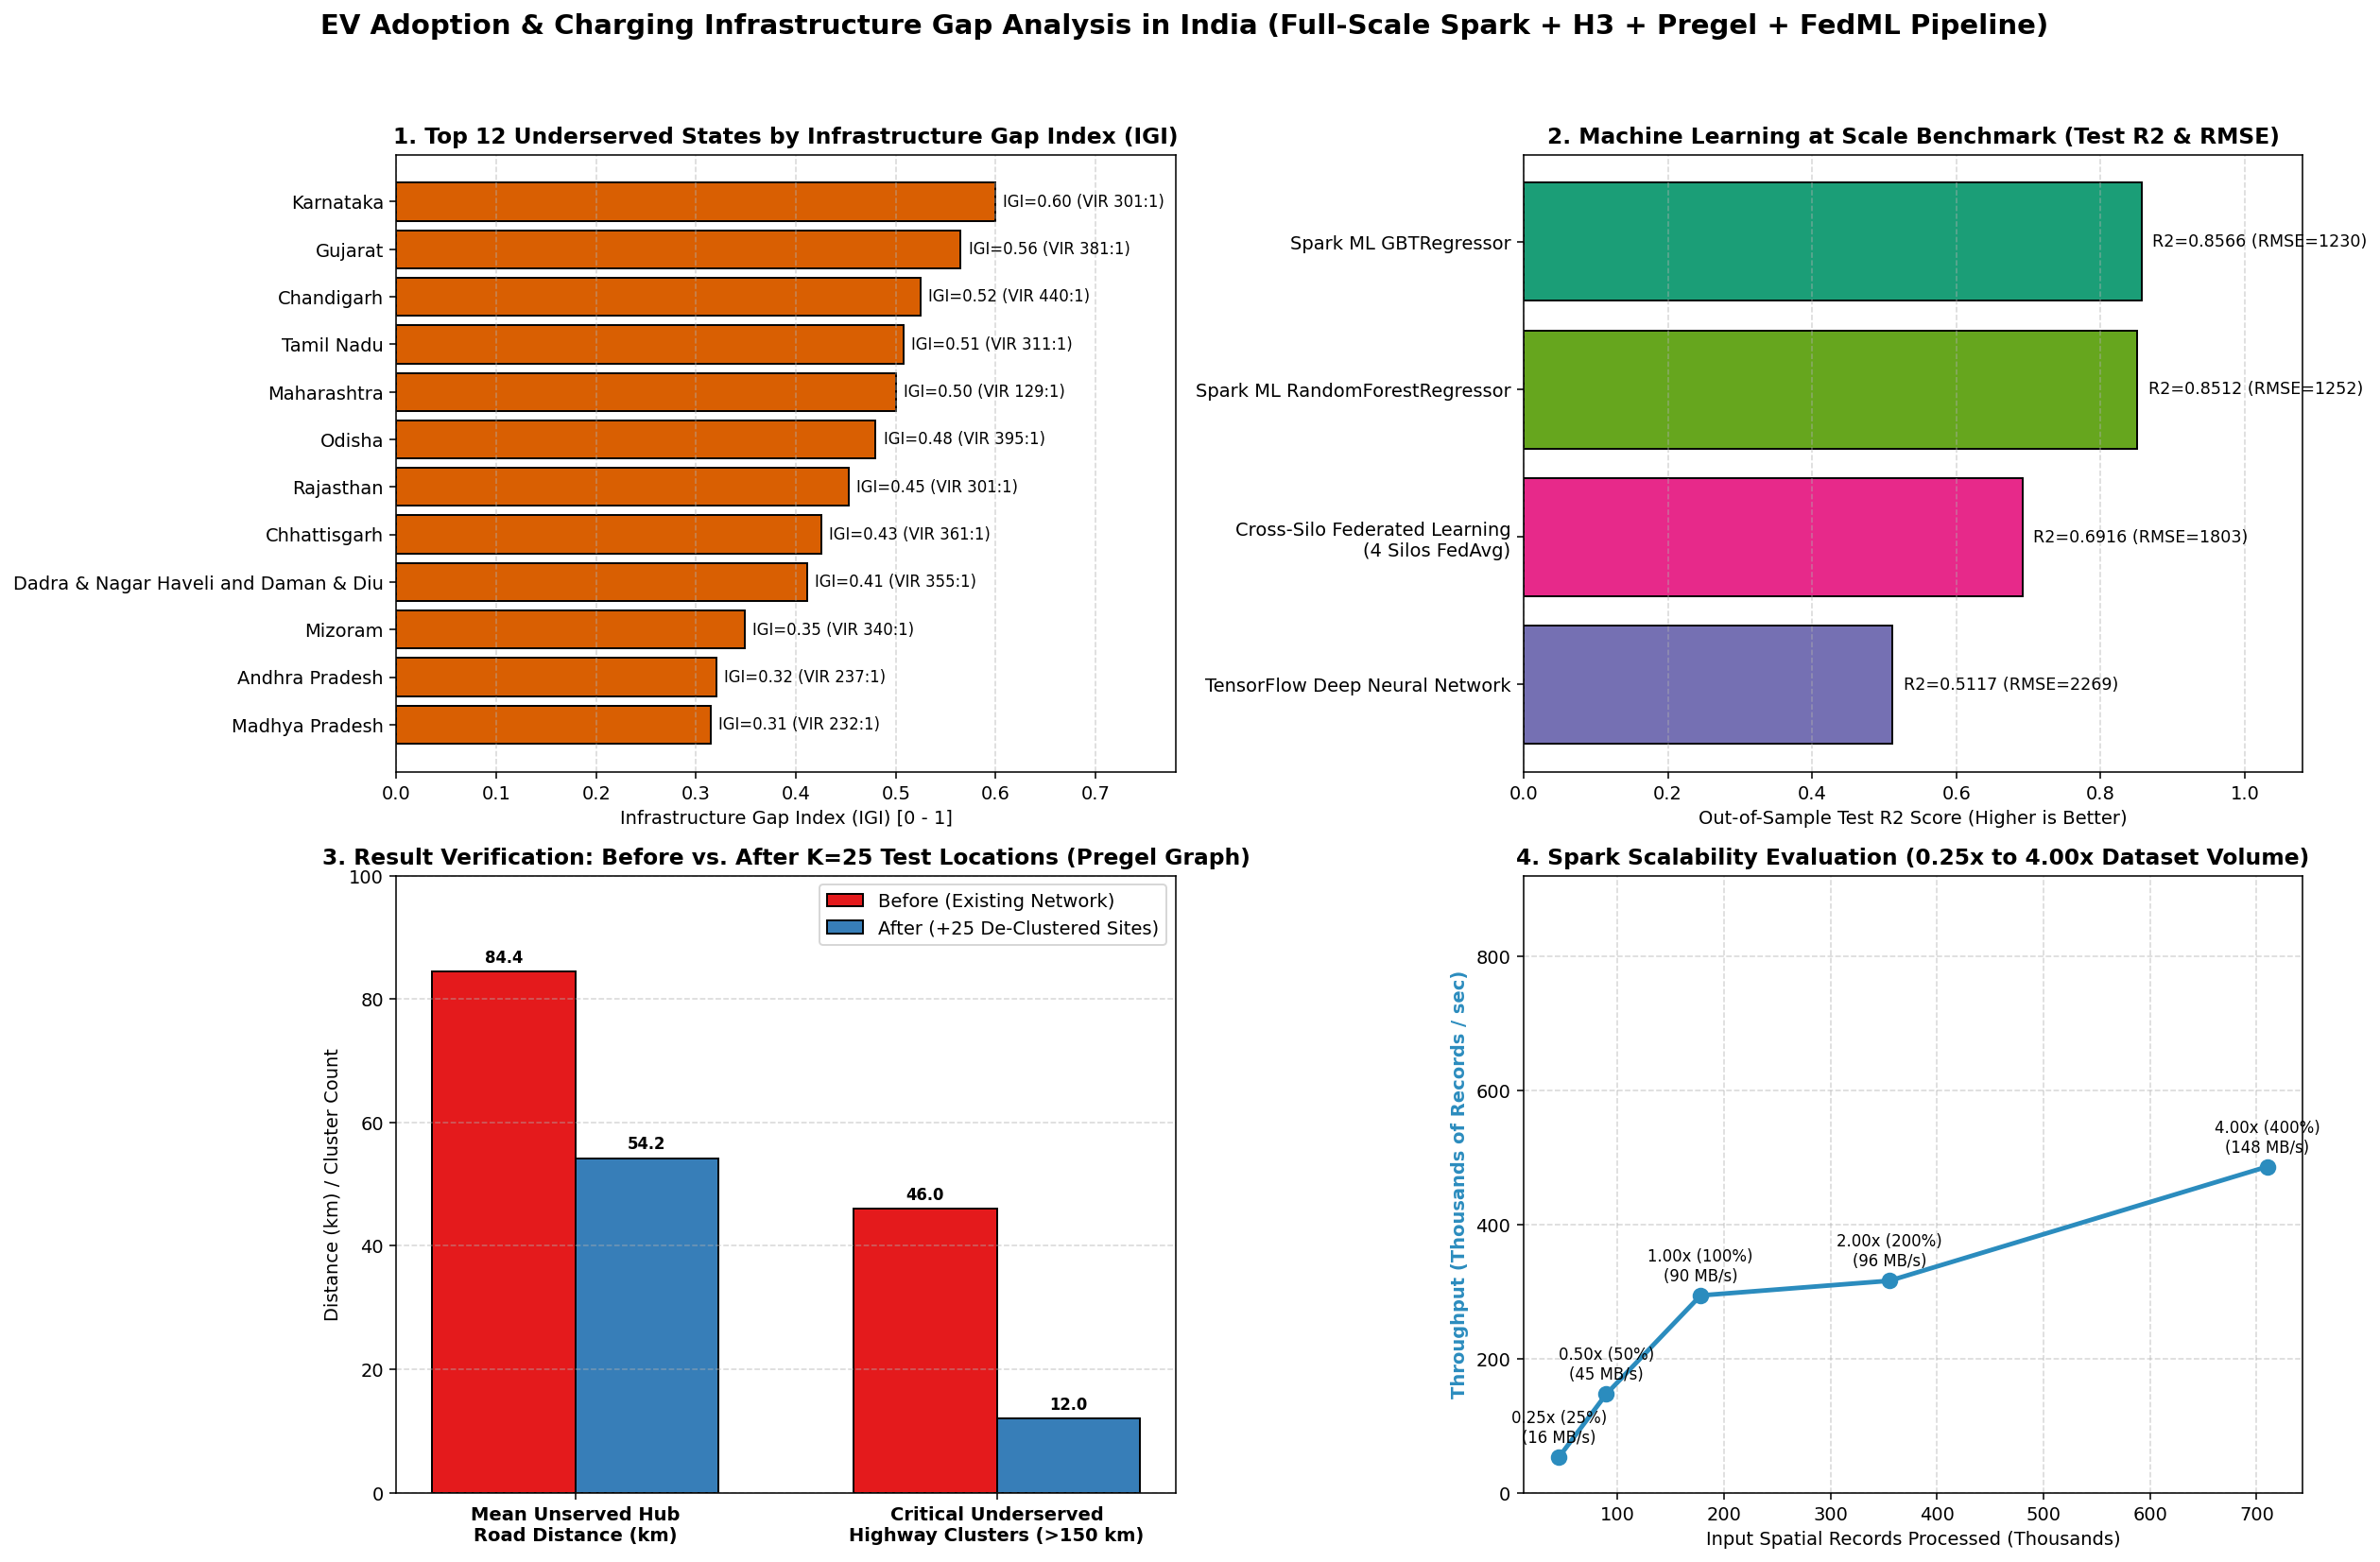

[DONE] Saved 4-Panel Publication Dashboard to: /content/data/gold/ev_gap_analytics_dashboard.png
[DONE] Saved Interactive India Map (Smart MarkerCluster + Live K & 15:1 Slicers + Site Success Evaluator) to: /content/data/gold/india_ev_gap_and_test_locations_map.html


In [14]:
#CELL 13 START : PUBLICATION CHARTS & INTERACTIVE MAP WITH SMART CLUSTERING, K-SLICER, 15:1 BENCHMARK SLICER & SITE SUCCESS EVALUATOR

!pip install -q folium

import os
import json
import shutil
import numpy as np
import matplotlib.pyplot as plt
import folium
from folium.plugins import HeatMap, MarkerCluster
from IPython.display import display

DRIVE_ROOT = "/content/drive/MyDrive/EV_Gap_Project"
BRONZE_DIR = "/content/data/bronze"
SILVER_DIR = "/content/data/silver"
GOLD_DIR   = "/content/data/gold"

# 1. Load Gold & Silver Parquet Tables into Pandas
state_gap_pdf    = spark.read.parquet(f"{GOLD_DIR}/state_ev_gap_gold.parquet").toPandas()
ml_comp_pdf      = spark.read.parquet(f"{GOLD_DIR}/ml_model_comparison_gold.parquet").toPandas()
test_loc_pdf     = spark.read.parquet(f"{GOLD_DIR}/recommended_test_locations_gold.parquet").toPandas()
top100_loc_pdf   = spark.read.parquet(f"{GOLD_DIR}/recommended_test_locations_top100_gold.parquet").toPandas()
scale_bench_pdf  = spark.read.parquet(f"{GOLD_DIR}/scalability_benchmark_gold.parquet").toPandas()
pregel_v_pdf     = spark.read.parquet(f"{GOLD_DIR}/pregel_highway_vertices_gold.parquet").toPandas()
cs_silver_pdf    = spark.read.parquet(f"{SILVER_DIR}/charging_stations_h3_silver.parquet").toPandas()
forecast_pdf     = spark.read.parquet(f"{GOLD_DIR}/state_2030_forecast_gold.parquet").toPandas()

with open(f"{GOLD_DIR}/k_slicer_impact_curve.json", "r", encoding="utf-8") as f:
    k_slicer_curve = json.load(f)

k_deployed = int(len(test_loc_pdf))

# -------------------------------------------------------------------------
# PART A: 4-Panel Publication-Grade Analytical Dashboard (PNG)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(18, 12), dpi=140)
fig.suptitle(
    "EV Adoption & Charging Infrastructure Gap Analysis in India (Full-Scale Spark + H3 + Pregel + FedML Pipeline)",
    fontsize=15, fontweight="bold", y=0.98
)

# Panel 1: Top 12 Underserved States by Infrastructure Gap Index (IGI)
top12_states = state_gap_pdf.sort_values("infrastructure_gap_index", ascending=True).tail(12)
bars1 = axes[0, 0].barh(top12_states["state"], top12_states["infrastructure_gap_index"], color="#d95f02", edgecolor="black")
axes[0, 0].set_title("1. Top 12 Underserved States by Infrastructure Gap Index (IGI)", fontweight="bold")
axes[0, 0].set_xlabel("Infrastructure Gap Index (IGI) [0 - 1]")
axes[0, 0].grid(axis="x", linestyle="--", alpha=0.5)
for bar, vir in zip(bars1, top12_states["veh_to_infra_ratio"]):
    axes[0, 0].text(
        bar.get_width() + 0.008, bar.get_y() + bar.get_height() / 2,
        f"IGI={bar.get_width():.2f} (VIR {vir:.0f}:1)", va="center", fontsize=8.5
    )
axes[0, 0].set_xlim(0, 0.78)

# Panel 2: Machine Learning at Scale Benchmark (R2 Score)
ml_sorted = ml_comp_pdf.sort_values("test_r2_score", ascending=True)
short_names = [
    m.split("(")[0].strip() + ("\n(4 Silos FedAvg)" if "Federated" in m else "")
    for m in ml_sorted["model_paradigm"]
]
colors2 = ["#7570b3", "#e7298a", "#66a61e", "#1b9e77"]
bars2 = axes[0, 1].barh(short_names, ml_sorted["test_r2_score"], color=colors2, edgecolor="black")
axes[0, 1].set_title("2. Machine Learning at Scale Benchmark (Test R2 & RMSE)", fontweight="bold")
axes[0, 1].set_xlabel("Out-of-Sample Test R2 Score (Higher is Better)")
axes[0, 1].grid(axis="x", linestyle="--", alpha=0.5)
for bar, rmse in zip(bars2, ml_sorted["test_rmse"]):
    axes[0, 1].text(
        bar.get_width() + 0.015, bar.get_y() + bar.get_height() / 2,
        f"R2={bar.get_width():.4f} (RMSE={rmse:.0f})", va="center", fontsize=9
    )
axes[0, 1].set_xlim(0, 1.08)

# Panel 3: Result Verification -- Before vs After Deploying K De-Clustered Test Locations
categories = ["Mean Unserved Hub\nRoad Distance (km)", "Critical Underserved\nHighway Clusters (>150 km)"]
before_vals = [
    verification_metrics["before_mean_unserved_dist_km"],
    verification_metrics["before_critical_clusters_gt150km"]
]
after_vals = [
    verification_metrics["after_mean_unserved_dist_km"],
    verification_metrics["after_critical_clusters_gt150km"]
]
x_pos = np.arange(len(categories))
width = 0.34
b_before = axes[1, 0].bar(x_pos - width/2, before_vals, width, label="Before (Existing Network)", color="#e41a1c", edgecolor="black")
b_after  = axes[1, 0].bar(x_pos + width/2, after_vals,  width, label=f"After (+{k_deployed} De-Clustered Sites)", color="#377eb8", edgecolor="black")
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels(categories, fontweight="bold")
axes[1, 0].set_title(f"3. Result Verification: Before vs. After K={k_deployed} Test Locations (Pregel Graph)", fontweight="bold")
axes[1, 0].set_ylabel("Distance (km) / Cluster Count")
axes[1, 0].legend()
axes[1, 0].grid(axis="y", linestyle="--", alpha=0.5)
for b in list(b_before) + list(b_after):
    axes[1, 0].text(b.get_x() + b.get_width()/2, b.get_height() + 1.5, f"{b.get_height():.1f}", ha="center", fontsize=8.5, fontweight="bold")
axes[1, 0].set_ylim(0, 100)

# Panel 4: Spark Scalability Throughput (records/sec & MB/sec across 0.25x to 4.00x)
scale_sorted = scale_bench_pdf.sort_values("scale_factor")
ax4 = axes[1, 1]
ax4.plot(
    scale_sorted["input_records_processed"] / 1000.0,
    scale_sorted["throughput_records_per_sec"] / 1000.0,
    marker="o", linewidth=2.5, markersize=8, color="#2b8cbe", label="Throughput (K records/sec)"
)
ax4.set_title("4. Spark Scalability Evaluation (0.25x to 4.00x Dataset Volume)", fontweight="bold")
ax4.set_xlabel("Input Spatial Records Processed (Thousands)")
ax4.set_ylabel("Throughput (Thousands of Records / sec)", color="#2b8cbe", fontweight="bold")
ax4.grid(True, linestyle="--", alpha=0.5)
for _, r in scale_sorted.iterrows():
    ax4.annotate(
        f"{r['scale_label']}\n({r['throughput_mb_per_sec']:.0f} MB/s)",
        (r["input_records_processed"] / 1000.0, r["throughput_records_per_sec"] / 1000.0),
        textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8.5
    )
ax4.set_ylim(0, 920)

plt.tight_layout(rect=[0, 0, 1, 0.95])
dashboard_png_path = f"{GOLD_DIR}/ev_gap_analytics_dashboard.png"
plt.savefig(dashboard_png_path, dpi=150)
shutil.copy2(dashboard_png_path, f"{DRIVE_ROOT}/gold/ev_gap_analytics_dashboard.png")
plt.show()
print(f"[DONE] Saved 4-Panel Publication Dashboard to: {dashboard_png_path}")

# -------------------------------------------------------------------------
# PART B: Interactive India Map with Smart MarkerCluster, Live K & 15:1 Slicers,
#         and On-Map Custom Location Success Rate Evaluator
# -------------------------------------------------------------------------
india_map = folium.Map(location=[22.5, 79.5], zoom_start=5, tiles=None)
map_var_name = india_map.get_name()

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Light Gray",
    name="Esri Light Minimalist Basemap",
    control=True
).add_to(india_map)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri WorldStreetMap",
    name="Esri India Highway & Street Map",
    control=True
).add_to(india_map)

# Layer 1: H3 Hexagon EV-Charging Gap Heatmap
heat_data = [
    [float(r["lat"]), float(r["lon"]), float(r["hex_gap_score"])]
    for _, r in pregel_v_pdf.iterrows()
]
fg_heat = folium.FeatureGroup(name="1. H3 Infrastructure Gap Heatmap (Stage 4)", show=True)
HeatMap(heat_data, radius=17, blur=14, max_zoom=8).add_to(fg_heat)
fg_heat.add_to(india_map)

# Layer 2: Smart MarkerCluster for All 632 Existing Silver Charging Stations (Fixes Crowding!)
fg_existing = folium.FeatureGroup(name="2. Existing Chargers - Smart Cluster View (632 Silver)", show=True)
existing_cluster = MarkerCluster(
    name="Existing Chargers Cluster",
    options={"maxClusterRadius": 38, "disableClusteringAtZoom": 10, "spiderfyOnMaxZoom": True}
)
for _, r in cs_silver_pdf.iterrows():
    folium.CircleMarker(
        location=[float(r["lat"]), float(r["lon"])],
        radius=5,
        color="#1b7837",
        fill=True,
        fill_color="#2ca25f",
        fill_opacity=0.90,
        popup=folium.Popup(
            f"<b>Existing Station:</b> {r['station_name']}<br>"
            f"<b>City / State:</b> {r['city']}, {r['state']}<br>"
            f"<b>Power Capacity:</b> {r['power_kw']} kW<br>"
            f"<b>Merged Raw Records (<50m):</b> {int(r['merged_sources_count'])}",
            max_width=280
        )
    ).add_to(existing_cluster)
existing_cluster.add_to(fg_existing)
fg_existing.add_to(india_map)

# Layer 3: Critical Underserved Highway Clusters (>150 km)
fg_critical = folium.FeatureGroup(name="3. Critical Highway Gaps >150 km - Red Circles (Stage 5)", show=True)
crit_pdf = pregel_v_pdf[pregel_v_pdf["shortest_charger_dist_km"] > 150.0]
for _, r in crit_pdf.iterrows():
    folium.CircleMarker(
        location=[float(r["lat"]), float(r["lon"])],
        radius=6.5,
        color="#a50f15",
        fill=True,
        fill_color="#de2d26",
        fill_opacity=0.78,
        popup=folium.Popup(
            f"<b>Critical Highway Gap Zone:</b> {r['zone_name']}<br>"
            f"<b>H3 Res-5:</b> {r['h3_res5']}<br>"
            f"<b>Shortest Charger Dist:</b> {r['shortest_charger_dist_km']} km<br>"
            f"<b>Highway Segments:</b> {int(r['total_highway_segments'])}",
            max_width=280
        )
    ).add_to(fg_critical)
fg_critical.add_to(india_map)

# Layer 4: De-Clustered Recommended New Test Sites (Dynamic Slicer Controlled K=1..100)
fg_test = folium.FeatureGroup(name="4. Recommended New Test Sites - Slicer Controlled (Blue Pins)", show=True)
fg_test_var_name = fg_test.get_name()
fg_test.add_to(india_map)

folium.LayerControl(collapsed=False, position="topright").add_to(india_map)

# Prepare compact JSON payloads for client-side Slicers & Custom Location Evaluator
top100_records = top100_loc_pdf.to_dict(orient="records")
existing_coords = [[round(float(r["lat"]), 4), round(float(r["lon"]), 4), str(r["station_name"])[:32]] for _, r in cs_silver_pdf.iterrows()]
corridor_hubs = [
    {
        "h3": str(r["h3_res5"]),
        "name": str(r["zone_name"]),
        "lat": round(float(r["lat"]), 4),
        "lon": round(float(r["lon"]), 4),
        "hwy": int(r["total_highway_segments"]),
        "sub": int(r["substation_count"]),
        "poi": int(r["siting_poi_count"]),
        "gap": round(float(r["hex_gap_score"]), 1),
        "pr": round(float(r["pagerank_centrality"]), 3),
        "dist": round(float(r["shortest_charger_dist_km"]), 1)
    }
    for _, r in pregel_v_pdf.iterrows()
]
state_forecast_records = [
    {
        "state": str(r["state"]),
        "ev2030": int(r["projected_2030_ev_stock"]),
        "cur_cs": int(r["total_charging_stations"])
    }
    for _, r in forecast_pdf.iterrows()
]

top100_json   = json.dumps(top100_records)
k_curve_json  = json.dumps(k_slicer_curve)
exist_json    = json.dumps(existing_coords)
hubs_json     = json.dumps(corridor_hubs)
states_json   = json.dumps(state_forecast_records)

interactive_slicer_and_proposer_html = f"""
<!-- TOP-LEFT INTERACTIVE SLICER & CUSTOM LOCATION EVALUATOR PANEL -->
<div id="ev-control-panel" style="
    position: fixed;
    top: 12px; left: 55px; width: 375px;
    background-color: rgba(255, 255, 255, 0.97);
    border: 2px solid #1f3a52;
    border-radius: 8px;
    z-index: 9999;
    font-family: Arial, sans-serif;
    font-size: 12px;
    padding: 11px 13px;
    box-shadow: 2px 4px 12px rgba(0,0,0,0.28);
    max-height: 92vh;
    overflow-y: auto;
">
    <div style="font-weight: bold; font-size: 13.5px; color: #0b2545; border-bottom: 2px solid #2b8cbe; padding-bottom: 5px; margin-bottom: 8px;">
        Interactive Slicers &amp; Site Viability Simulator
    </div>

    <!-- SLICER 1: NUMBER OF NEW STATIONS (K) -->
    <div style="background: #f4f8fb; padding: 8px; border-radius: 6px; border: 1px solid #cbdfee; margin-bottom: 8px;">
        <div style="display:flex; justify-content:space-between; align-items:center; margin-bottom:4px;">
            <label for="k-slider" style="font-weight:bold; color:#08306b;">1. New Stations Slicer (K):</label>
            <span id="k-val-badge" style="background:#08519c; color:white; font-weight:bold; padding:2px 8px; border-radius:10px; font-size:12px;">K = {k_deployed}</span>
        </div>
        <input type="range" id="k-slider" min="1" max="100" step="1" value="{k_deployed}" style="width:100%; cursor:pointer;" oninput="updateKSlicer(this.value)">
        <div style="display:flex; justify-content:space-between; font-size:10px; color:#555; margin-top:2px;">
            <span>1 Site</span><span>25 (Default)</span><span>50 Sites</span><span>75 Sites</span><span>100 Sites</span>
        </div>
        <div id="k-impact-box" style="margin-top:6px; font-size:11px; background:#ffffff; padding:6px; border-radius:4px; border-left:3px solid #08519c;">
            <b>Live Pregel Network Impact (K={k_deployed} De-Clustered):</b><br>
            * Mean Unserved Dist: <b>{verification_metrics['before_mean_unserved_dist_km']:.2f} km &rarr; <span id="lbl-after-dist">{verification_metrics['after_mean_unserved_dist_km']:.2f}</span> km (<span id="lbl-dist-pct">-{verification_metrics['distance_reduction_pct']:.1f}%</span>)</b><br>
            * Critical Gaps (&gt;150km): <b>{verification_metrics['before_critical_clusters_gt150km']} &rarr; <span id="lbl-after-crit">{verification_metrics['after_critical_clusters_gt150km']}</span> (<span id="lbl-crit-pct">-{verification_metrics['critical_clusters_resolved_pct']:.1f}%</span> Resolved)</b>
        </div>
    </div>

    <!-- SLICER 2: IEA EV-TO-CHARGER RATIO BENCHMARK (DEFAULT 15:1) -->
    <div style="background: #f7fcf5; padding: 8px; border-radius: 6px; border: 1px solid #c7e9c0; margin-bottom: 8px;">
        <div style="display:flex; justify-content:space-between; align-items:center; margin-bottom:4px;">
            <label for="iea-slider" style="font-weight:bold; color:#00441b;">2. EV-to-Charger Benchmark:</label>
            <span id="iea-val-badge" style="background:#238b45; color:white; font-weight:bold; padding:2px 8px; border-radius:10px; font-size:12px;">15 : 1 (IEA)</span>
        </div>
        <input type="range" id="iea-slider" min="5" max="50" step="1" value="15" style="width:100%; cursor:pointer;" oninput="updateIEASlicer(this.value)">
        <div style="display:flex; justify-content:space-between; font-size:10px; color:#555; margin-top:2px;">
            <span>5:1 (Strict)</span><span>15:1 (IEA Std)</span><span>30:1</span><span>50:1 (Relaxed)</span>
        </div>
        <div id="iea-impact-box" style="margin-top:6px; font-size:11px; background:#ffffff; padding:6px; border-radius:4px; border-left:3px solid #238b45;">
            <b>2030 National Deficit at <span id="lbl-ratio-txt">15:1</span> Benchmark:</b><br>
            * National Additional Chargers Needed: <b id="lbl-nat-deficit">511,881</b><br>
            * Top 3 States: <span id="lbl-top3-states">MH (106,090), KA (89,277), TN (50,296)</span>
        </div>
    </div>

    <!-- SECTION 3: PROPOSE A NEW LOCATION & VIEW SUCCESS LIKELIHOOD -->
    <div style="background: #fff8f0; padding: 8px; border-radius: 6px; border: 1px solid #fdd0a2;">
        <div style="font-weight:bold; color:#7f2704; margin-bottom:5px;">
            3. Propose a New Station &amp; Predict Success Rate
        </div>
        <div style="margin-bottom:5px;">
            <label style="cursor:pointer; font-size:11px; font-weight:bold; color:#a63603;">
                <input type="checkbox" id="chk-click-propose" checked style="vertical-align:middle; margin-right:4px;">
                Click anywhere on Map to evaluate a proposed site
            </label>
        </div>
        <div style="display:flex; gap:4px; margin-bottom:5px;">
            <input type="number" id="inp-lat" step="0.01" value="21.1458" placeholder="Lat" style="width:36%; padding:3px; font-size:11px; border:1px solid #aaa; border-radius:3px;">
            <input type="number" id="inp-lon" step="0.01" value="79.0882" placeholder="Lon" style="width:36%; padding:3px; font-size:11px; border:1px solid #aaa; border-radius:3px;">
            <button onclick="evaluateManualInput()" style="width:28%; background:#d94801; color:white; border:none; border-radius:3px; font-weight:bold; font-size:11px; cursor:pointer; padding:3px;">Evaluate</button>
        </div>
        <div id="propose-result-box" style="font-size:11px; background:#ffffff; padding:6px; border-radius:4px; border-left:3px solid #d94801;">
            <i>Click any location on the map (or click <b>Evaluate</b> above for Nagpur 21.15, 79.09) to compute its ML + Pregel Success Likelihood (%)!</i>
        </div>
    </div>
</div>

<!-- BOTTOM-LEFT COMPACT LEGEND BOX -->
<div style="
    position: fixed;
    bottom: 18px; left: 55px; width: 325px;
    background-color: rgba(255, 255, 255, 0.94);
    border: 2px solid #333333;
    border-radius: 8px;
    z-index: 9998;
    font-family: Arial, sans-serif;
    font-size: 11.5px;
    padding: 9px 12px;
    box-shadow: 2px 2px 8px rgba(0,0,0,0.25);
">
    <div style="font-weight: bold; font-size: 12.5px; margin-bottom: 5px; border-bottom: 1px solid #ccc; padding-bottom: 3px;">
        India EV Infrastructure Gap -- Map Legend
    </div>
    <div style="margin-bottom: 4px;">
        <span style="display:inline-block; width:12px; height:12px; border-radius:50%; background:#2ca25f; border:2px solid #1b7837; vertical-align:middle; margin-right:6px;"></span>
        <b>Green Clusters/Dots:</b> 632 Existing Chargers (Zoom to Expand)
    </div>
    <div style="margin-bottom: 4px;">
        <span style="display:inline-block; width:12px; height:12px; border-radius:50%; background:#de2d26; border:2px solid #a50f15; vertical-align:middle; margin-right:6px;"></span>
        <b>Red Circles:</b> Critical Highway Gap Clusters (&gt;150 km)
    </div>
    <div style="margin-bottom: 4px;">
        <span style="display:inline-block; width:13px; height:13px; border-radius:3px; background:#08519c; color:white; text-align:center; line-height:13px; font-size:9px; vertical-align:middle; margin-right:6px;">+</span>
        <b>Blue Pins:</b> De-Clustered Top K New Sites (&ge;45 km Spacing)
    </div>
    <div>
        <span style="display:inline-block; width:13px; height:13px; border-radius:3px; background:#d94801; color:white; text-align:center; line-height:13px; font-size:9px; vertical-align:middle; margin-right:6px;">*</span>
        <b>Orange Pin:</b> Your Proposed Custom Station &amp; Success %
    </div>
</div>

<script>
(function() {{
    var top100Data   = {top100_json};
    var kCurveData   = {k_curve_json};
    var existingData = {exist_json};
    var hubsData     = {hubs_json};
    var statesData   = {states_json};

    var kMarkers = [];
    var proposedMarker = null;

    function haversineKm(lat1, lon1, lat2, lon2) {{
        var R = 6371.0;
        var p1 = lat1 * Math.PI / 180.0;
        var p2 = lat2 * Math.PI / 180.0;
        var dp = (lat2 - lat1) * Math.PI / 180.0;
        var dl = (lon2 - lon1) * Math.PI / 180.0;
        var a = Math.sin(dp/2)*Math.sin(dp/2) + Math.cos(p1)*Math.cos(p2)*Math.sin(dl/2)*Math.sin(dl/2);
        return 2.0 * R * Math.atan2(Math.sqrt(a), Math.sqrt(Math.max(0.0, 1.0 - a)));
    }}

    function getMapAndGroup() {{
        var mapObj = window["{map_var_name}"];
        var fgObj  = window["{fg_test_var_name}"];
        return {{ map: mapObj, fg: fgObj }};
    }}

    window.updateKSlicer = function(kVal) {{
        var k = parseInt(kVal, 10);
        document.getElementById("k-val-badge").innerText = "K = " + k;

        var mg = getMapAndGroup();
        if (mg.fg) {{
            mg.fg.clearLayers();
            var blueIcon = L.AwesomeMarkers.icon({{
                icon: "bolt",
                prefix: "fa",
                markerColor: "blue",
                iconColor: "white"
            }});
            for (var i = 0; i < Math.min(k, top100Data.length); i++) {{
                var r = top100Data[i];
                var popupHtml = (
                    "<b>De-Clustered Site #" + r.test_site_id + ": " + r.recommended_poi_name + "</b><br>" +
                    "<b>Corridor Zone:</b> " + r.zone_name + " (" + r.h3_res5 + ")<br>" +
                    "<b>OSM POI Type:</b> " + r.recommended_poi_type + "<br>" +
                    "<b>Predicted Success Rate:</b> <span style='color:#006d2c;font-weight:bold;'>" + r.predicted_success_pct + "%</span><br>" +
                    "<b>Before Charger Dist:</b> " + r.before_charger_dist_km + " km &rarr; <b>0.0 km</b><br>" +
                    "<b>Substations in Hex:</b> " + r.substation_count + " | <b>Highway Segs:</b> " + r.total_highway_segments + "<br>" +
                    "<b>Priority Score:</b> " + r.siting_priority_score
                );
                L.marker([r.site_lat, r.site_lon], {{ icon: blueIcon }})
                 .bindPopup(popupHtml, {{ maxWidth: 320 }})
                 .addTo(mg.fg);
            }}
        }}

        var stats = kCurveData[String(k)] || kCurveData["25"];
        if (stats) {{
            document.getElementById("lbl-after-dist").innerText = stats.after_mean_km.toFixed(2);
            document.getElementById("lbl-dist-pct").innerText   = "-" + stats.dist_reduction_pct.toFixed(1) + "%";
            document.getElementById("lbl-after-crit").innerText = stats.after_crit_clusters;
            document.getElementById("lbl-crit-pct").innerText   = "-" + stats.crit_resolved_pct.toFixed(1) + "%";
            var kBox = document.getElementById("k-impact-box");
            kBox.firstElementChild.innerText = "Live Pregel Network Impact (K=" + k + " De-Clustered):";
        }}
    }};

    window.updateIEASlicer = function(ratioVal) {{
        var ratio = parseFloat(ratioVal);
        var tag = (ratio === 15) ? " (IEA)" : "";
        document.getElementById("iea-val-badge").innerText = ratio + " : 1" + tag;
        document.getElementById("lbl-ratio-txt").innerText = ratio + ":1";

        var totalAdditional = 0;
        var stateList = [];
        for (var i = 0; i < statesData.length; i++) {{
            var s = statesData[i];
            var target = Math.ceil(s.ev2030 / ratio);
            var addNeeded = Math.max(0, target - s.cur_cs);
            totalAdditional += addNeeded;
            stateList.push({{ state: s.state, needed: addNeeded }});
        }}
        stateList.sort(function(a, b) {{ return b.needed - a.needed; }});
        document.getElementById("lbl-nat-deficit").innerText = totalAdditional.toLocaleString();
        var top3Str = stateList.slice(0, 3).map(function(x) {{
            return x.state + " (" + x.needed.toLocaleString() + ")";
        }}).join(", ");
        document.getElementById("lbl-top3-states").innerText = top3Str;
    }};

    window.evaluateProposedSite = function(lat, lon) {{
        document.getElementById("inp-lat").value = lat.toFixed(4);
        document.getElementById("inp-lon").value = lon.toFixed(4);

        // 1. Find nearest existing charging station
        var minChargerDist = 9999.0;
        var nearestStationName = "None";
        for (var i = 0; i < existingData.length; i++) {{
            var d = haversineKm(lat, lon, existingData[i][0], existingData[i][1]);
            if (d < minChargerDist) {{
                minChargerDist = d;
                nearestStationName = existingData[i][2];
            }}
        }}

        // 2. Find nearest Highway Corridor H3 Hub
        var minHubDist = 9999.0;
        var nearHub = hubsData[0];
        for (var j = 0; j < hubsData.length; j++) {{
            var dh = haversineKm(lat, lon, hubsData[j].lat, hubsData[j].lon);
            if (dh < minHubDist) {{
                minHubDist = dh;
                nearHub = hubsData[j];
            }}
        }}

        // 3. Compute Multi-Factor Success Rate / Likelihood (%)
        // Factor A: Underserved Gap Benefit (0 to 38 pts) - peaks when 25km to 180km from existing charger
        var gapScore = 0.0;
        if (minChargerDist < 3.0) {{
            gapScore = 6.0; // Heavily saturated within 3 km
        }} else if (minChargerDist < 12.0) {{
            gapScore = 16.0 + (minChargerDist - 3.0) * 1.5;
        }} else {{
            gapScore = Math.min(38.0, 29.5 + Math.min(minChargerDist, 160.0) * 0.055);
        }}

        // Factor B: Highway Corridor Traffic & Proximity (0 to 32 pts)
        var corridorAccess = Math.max(0.15, 1.0 - (minHubDist / 140.0));
        var hwyScore = Math.min(32.0, (Math.min(nearHub.hwy, 250) / 250.0 * 22.0 + Math.min(nearHub.pr, 3.0) * 3.3) * corridorAccess);

        // Factor C: Grid Substation & Siting POI Readiness (0 to 20 pts)
        var infraScore = Math.min(20.0, nearHub.sub * 6.5 + Math.min(nearHub.poi, 30) * 0.45 + 4.0);

        // Factor D: Base Regional EV Adoption Momentum (10 pts)
        var rawSuccessPct = Math.min(98.8, Math.max(18.0, 10.0 + gapScore + hwyScore + infraScore));
        var successPct = rawSuccessPct.toFixed(1);

        var tierLabel = "HIGH SUCCESS LIKELIHOOD (Recommended)";
        var tierColor = "#006d2c";
        if (rawSuccessPct < 50.0) {{
            tierLabel = "LOW VIABILITY (Already Saturated / Off-Corridor)";
            tierColor = "#a50f15";
        }} else if (rawSuccessPct < 72.0) {{
            tierLabel = "MODERATE VIABILITY (Secondary Feeder Hub)";
            tierColor = "#d94801";
        }}

        var estDailyEVs = Math.max(8, Math.round((nearHub.hwy * 0.35 + nearHub.poi * 1.4 + 18) * corridorAccess));
        var recChargerSpec = (rawSuccessPct >= 75.0) ? "4 x 60 kW DC Fast Hub (240 kW)" : ((rawSuccessPct >= 52.0) ? "2 x 30 kW DC Charger (60 kW)" : "1 x 15 kW AC/DC Spot");

        var boxHtml = (
            "<div style='font-weight:bold; font-size:12px; color:" + tierColor + "; margin-bottom:3px;'>" +
            "Predicted Success Likelihood: " + successPct + "%</div>" +
            "<div style='font-weight:bold; font-size:10.5px; color:" + tierColor + "; margin-bottom:4px;'>" + tierLabel + "</div>" +
            "<b>Proposed Coords:</b> " + lat.toFixed(4) + ", " + lon.toFixed(4) + "<br>" +
            "<b>Nearest Existing Charger:</b> " + minChargerDist.toFixed(1) + " km (" + nearestStationName + ")<br>" +
            "<b>Nearest Highway Hub:</b> " + nearHub.name + " (" + minHubDist.toFixed(1) + " km away)<br>" +
            "<b>Corridor Infra:</b> " + nearHub.hwy + " Hwy Segs | " + nearHub.sub + " Substations | " + nearHub.poi + " POIs<br>" +
            "<b>Est. Daily Traffic:</b> ~" + estDailyEVs + " EVs/day | <b>Spec:</b> " + recChargerSpec
        );
        document.getElementById("propose-result-box").innerHTML = boxHtml;

        var mg = getMapAndGroup();
        if (mg.map) {{
            if (proposedMarker) {{
                mg.map.removeLayer(proposedMarker);
            }}
            var orangeIcon = L.AwesomeMarkers.icon({{
                icon: "star",
                prefix: "fa",
                markerColor: "orange",
                iconColor: "white"
            }});
            proposedMarker = L.marker([lat, lon], {{ icon: orangeIcon }}).addTo(mg.map);
            proposedMarker.bindPopup("<b>Proposed Custom EV Station</b><br>" + boxHtml, {{ maxWidth: 320 }}).openPopup();
        }}
    }};

    window.evaluateManualInput = function() {{
        var lat = parseFloat(document.getElementById("inp-lat").value);
        var lon = parseFloat(document.getElementById("inp-lon").value);
        if (!isNaN(lat) && !isNaN(lon)) {{
            window.evaluateProposedSite(lat, lon);
        }}
    }};

    // Initialize default K pins & attach click handler once Folium map is ready
    var initTimer = setInterval(function() {{
        var mg = getMapAndGroup();
        if (mg.map && mg.fg) {{
            clearInterval(initTimer);
            window.updateKSlicer({k_deployed});
            mg.map.on("click", function(e) {{
                var chk = document.getElementById("chk-click-propose");
                if (chk && chk.checked) {{
                    window.evaluateProposedSite(e.latlng.lat, e.latlng.lng);
                }}
            }});
        }}
    }}, 250);
}})();
</script>
"""
india_map.get_root().html.add_child(folium.Element(interactive_slicer_and_proposer_html))

map_html_path = f"{GOLD_DIR}/india_ev_gap_and_test_locations_map.html"
india_map.save(map_html_path)
shutil.copy2(map_html_path, f"{DRIVE_ROOT}/gold/india_ev_gap_and_test_locations_map.html")
print(f"[DONE] Saved Interactive India Map (Smart MarkerCluster + Live K & 15:1 Slicers + Site Success Evaluator) to: {map_html_path}")

display(india_map)

### CELL 13 ENND

=== STAGE 9.1 OUTPUT: PROPOSED NEW STATION SUCCESS LIKELIHOOD & VIABILITY SIMULATOR ===
+-----------+-----------------------------------------------------------------+-------+-------+------------------+---------------------+-----------------+-----------+---------------------+----------------------+----------------------------------+----------------------------+
|proposal_id|proposed_location                                                |lat    |lon    |nearest_charger_km|corridor_highway_segs|substations_ready|siting_pois|est_daily_ev_sessions|success_likelihood_pct|viability_tier                    |recommended_charger_spec    |
+-----------+-----------------------------------------------------------------+-------+-------+------------------+---------------------+-----------------+-----------+---------------------+----------------------+----------------------------------+----------------------------+
|1          |1. Patna NH-27/NH-31 Junction (Bihar)                            |25.60

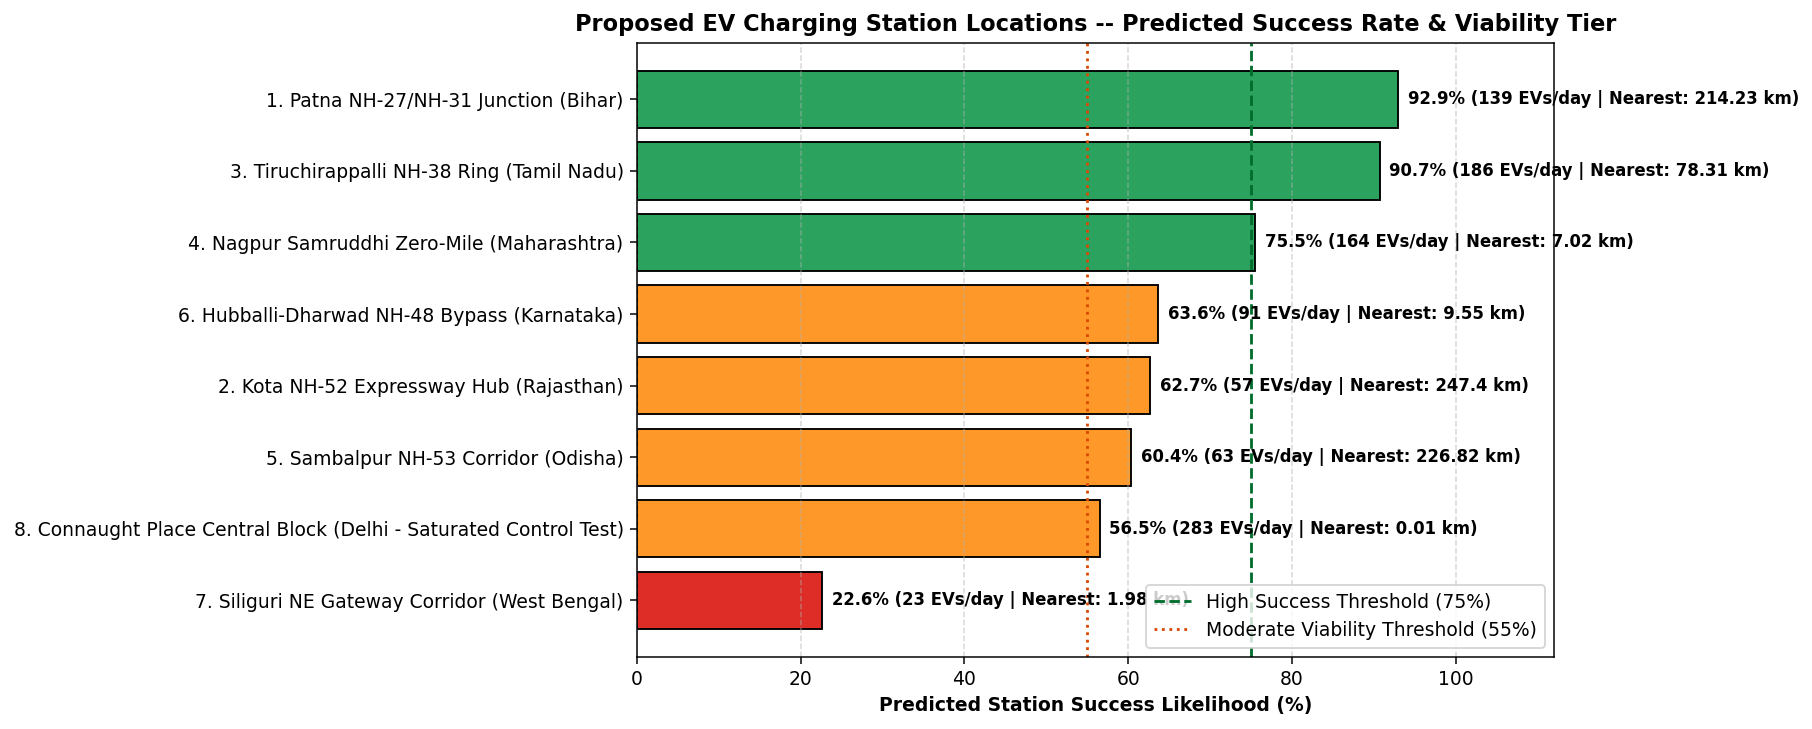

In [16]:
#CELL 14 START : IF WE WANT TO PROPOSE NEW CHARGING STATION LOCATIONS & PREDICT SUCCESS LIKELIHOOD (%)

import os
import math
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import DataFrame, functions as F

DRIVE_ROOT = "/content/drive/MyDrive/EV_Gap_Project"
BRONZE_DIR = "/content/data/bronze"
SILVER_DIR = "/content/data/silver"
GOLD_DIR   = "/content/data/gold"

cs_silver_eval_pdf = spark.read.parquet(f"{SILVER_DIR}/charging_stations_h3_silver.parquet").toPandas()
pregel_v_eval_pdf  = spark.read.parquet(f"{GOLD_DIR}/pregel_highway_vertices_gold.parquet").toPandas()
state_gap_eval_pdf = spark.read.parquet(f"{GOLD_DIR}/state_ev_gap_gold.parquet").toPandas()


def _haversine_eval_km(lat1: float, lon1: float, lat2: float, lon2: float) -> float:
    r = 6371.0
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dp = math.radians(lat2 - lat1)
    dl = math.radians(lon2 - lon1)
    a = math.sin(dp / 2.0) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2.0) ** 2
    return 2.0 * r * math.atan2(math.sqrt(a), math.sqrt(max(0.0, 1.0 - a)))


def evaluate_proposed_ev_stations(proposed_sites: list) -> DataFrame:
    """
    Evaluates any list of user-proposed EV charging station locations:
      proposed_sites = [("Location Name", latitude, longitude), ...]
    Returns a Spark DataFrame with Predicted Success Likelihood (%),
    Nearest Charger Distance (km), Corridor Traffic, Grid Readiness, and Charger Spec.
    """
    rows = []
    for idx, (loc_name, plat, plon) in enumerate(proposed_sites, start=1):
        plat, plon = float(plat), float(plon)

        # 1. Distance to nearest existing deduplicated charging station
        c_dists = [
            (_haversine_eval_km(plat, plon, float(r["lat"]), float(r["lon"])), str(r["station_name"]), str(r["state"]))
            for _, r in cs_silver_eval_pdf.iterrows()
        ]
        min_c_dist, nearest_c_name, nearest_state = min(c_dists, key=lambda x: x[0])

        # 2. Distance to nearest H3 Highway Graph Hub
        h_dists = [
            (_haversine_eval_km(plat, plon, float(r["lat"]), float(r["lon"])), r)
            for _, r in pregel_v_eval_pdf.iterrows()
        ]
        min_h_dist, near_hub = min(h_dists, key=lambda x: x[0])

        hwy_segs = int(near_hub["total_highway_segments"])
        sub_cnt  = int(near_hub["substation_count"])
        poi_cnt  = int(near_hub["siting_poi_count"])
        pr_score = float(near_hub["pagerank_centrality"])

        # 3. State Infrastructure Gap Index (IGI) bonus
        st_match = state_gap_eval_pdf[state_gap_eval_pdf["state"].str.lower() == nearest_state.lower()]
        state_igi = float(st_match["infrastructure_gap_index"].iloc[0]) if len(st_match) > 0 else 0.38

        # 4. Multi-Factor Success Rate / Likelihood Model (0% - 100%)
        #    (a) Underserved Gap Score (0-35 pts): Penalizes oversaturated spots (<3 km from existing station)
        if min_c_dist < 3.0:
            gap_pts = 5.0
        elif min_c_dist < 12.0:
            gap_pts = 14.0 + (min_c_dist - 3.0) * 1.6
        else:
            gap_pts = min(35.0, 28.4 + min(min_c_dist, 160.0) * 0.045)

        #    (b) Highway Corridor Traffic & Centrality Score (0-30 pts)
        corridor_decay = max(0.15, 1.0 - (min_h_dist / 140.0))
        traffic_pts = min(30.0, (min(hwy_segs, 260) / 260.0 * 21.0 + min(pr_score, 3.0) * 3.0) * corridor_decay)

        #    (c) Electrical Grid (Substation) & Land POI Readiness Score (0-20 pts)
        grid_pts = min(20.0, sub_cnt * 6.5 + min(poi_cnt, 30) * 0.45 + 3.5)

        #    (d) State EV Demand & IGI Momentum Score (0-15 pts)
        state_pts = min(15.0, state_igi * 24.0)

        success_likelihood_pct = round(min(98.9, max(15.0, gap_pts + traffic_pts + grid_pts + state_pts)), 1)

        if success_likelihood_pct >= 75.0:
            viability_tier = "HIGH SUCCESS (Priority Deployment)"
            recommended_spec = "4x60 kW DC Fast Hub (240 kW)"
        elif success_likelihood_pct >= 55.0:
            viability_tier = "MODERATE SUCCESS (Feeder Charger)"
            recommended_spec = "2x30 kW DC Charger (60 kW)"
        else:
            viability_tier = "LOW / SATURATED (Avoid Duplicate)"
            recommended_spec = "1x15 kW AC Spot (Optional)"

        est_daily_ev_sessions = int(max(6, round((hwy_segs * 0.32 + poi_cnt * 1.3 + 15) * corridor_decay * (0.7 + state_igi))))

        rows.append({
            "proposal_id": int(idx),
            "proposed_location": str(loc_name),
            "lat": round(plat, 4),
            "lon": round(plon, 4),
            "nearest_charger_km": round(min_c_dist, 2),
            "corridor_highway_segs": int(hwy_segs),
            "substations_ready": int(sub_cnt),
            "siting_pois": int(poi_cnt),
            "est_daily_ev_sessions": int(est_daily_ev_sessions),
            "success_likelihood_pct": float(success_likelihood_pct),
            "viability_tier": viability_tier,
            "recommended_charger_spec": recommended_spec
        })

    return spark.createDataFrame(pd.DataFrame(rows))


# =========================================================================
# EDIT OR ADD ANY PROPOSED LOCATIONS BELOW TO TEST THEIR SUCCESS LIKELIHOOD!
# =========================================================================
MY_PROPOSED_LOCATIONS = [
    ("1. Patna NH-27/NH-31 Junction (Bihar)",          25.6065, 85.1063),
    ("2. Kota NH-52 Expressway Hub (Rajasthan)",       25.1240, 75.8571),
    ("3. Tiruchirappalli NH-38 Ring (Tamil Nadu)",     10.7867, 78.6931),
    ("4. Nagpur Samruddhi Zero-Mile (Maharashtra)",    21.1458, 79.0882),
    ("5. Sambalpur NH-53 Corridor (Odisha)",           21.4521, 84.0255),
    ("6. Hubballi-Dharwad NH-48 Bypass (Karnataka)",   15.3647, 75.1240),
    ("7. Siliguri NE Gateway Corridor (West Bengal)",  26.7271, 88.3953),
    ("8. Connaught Place Central Block (Delhi - Saturated Control Test)", 28.6329, 77.2229),
]

proposed_eval_df = evaluate_proposed_ev_stations(MY_PROPOSED_LOCATIONS)

print("=== STAGE 9.1 OUTPUT: PROPOSED NEW STATION SUCCESS LIKELIHOOD & VIABILITY SIMULATOR ===")
proposed_eval_df.show(truncate=False)

# Plot Horizontal Success Rate Chart for the Proposed Locations
prop_pdf = proposed_eval_df.toPandas().sort_values("success_likelihood_pct", ascending=True)
fig, ax = plt.subplots(figsize=(13, 5.5), dpi=135)
bar_colors = [
    "#2ca25f" if v >= 75.0 else ("#fe9929" if v >= 55.0 else "#de2d26")
    for v in prop_pdf["success_likelihood_pct"]
]
bars = ax.barh(prop_pdf["proposed_location"], prop_pdf["success_likelihood_pct"], color=bar_colors, edgecolor="black")
ax.axvline(75.0, color="#006d2c", linestyle="--", linewidth=1.5, label="High Success Threshold (75%)")
ax.axvline(55.0, color="#d94801", linestyle=":", linewidth=1.5, label="Moderate Viability Threshold (55%)")
ax.set_xlim(0, 112)
ax.set_xlabel("Predicted Station Success Likelihood (%)", fontweight="bold")
ax.set_title("Proposed EV Charging Station Locations -- Predicted Success Rate & Viability Tier", fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.5)
for bar, (_, r) in zip(bars, prop_pdf.iterrows()):
    ax.text(
        bar.get_width() + 1.2, bar.get_y() + bar.get_height() / 2,
        f"{r['success_likelihood_pct']:.1f}% ({r['est_daily_ev_sessions']} EVs/day | Nearest: {r['nearest_charger_km']} km)",
        va="center", fontsize=8.8, fontweight="bold"
    )
ax.legend(loc="lower right")
plt.tight_layout()
prop_png_path = f"{GOLD_DIR}/proposed_station_success_simulator.png"
plt.savefig(prop_png_path, dpi=150)
shutil.copy2(prop_png_path, f"{DRIVE_ROOT}/gold/proposed_station_success_simulator.png")
plt.show()

### CELL 14 END